# Biodiversity and Food Security: Are Diverse Agricultural Landscapes More Stable?

## Step 0 — Setup

In [1]:
import os, time, zipfile, warnings, codecs, re, glob, logging
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import country_converter as coco

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=RuntimeWarning)

BASE = os.path.abspath('.')                      # folder that contains data_downloads/
DATA = os.path.join(BASE, 'data_downloads')      # <-- your downloaded files
OUT = os.path.join(BASE, 'outputs')
FIG = os.path.join(OUT, 'figs')
CACHE = os.path.join(OUT, 'cache')
for d in (OUT, FIG, CACHE):
    os.makedirs(d, exist_ok=True)
Y0, Y1 = 2000, 2020
YEARS = list(range(Y0, Y1 + 1))
cc = coco.CountryConverter()
logging.getLogger('country_converter').setLevel(logging.ERROR)
sns.set_theme(style='whitegrid', context='notebook')

def find(pattern, required=True):
    hits = sorted(glob.glob(os.path.join(DATA, pattern)) + glob.glob(os.path.join(BASE, 'datasets', pattern)))
    if not hits and required:
        raise FileNotFoundError(f'No file matching {pattern} in {DATA}')
    return hits[0] if hits else None

FAO_ZIP = find('*Production_Crops_Livestock*.zip')
DATASETS = os.path.join(BASE, 'datasets')        # second place we look for input files
LANDUSE_ZIP = find('*LandUse*.zip', required=False)
WC_TIF = find('ESA_WorldCover*.tif', required=False)
NE_ZIP = find('ne_50m_admin_0_countries*.zip')
for k, v in dict(FAO_ZIP=FAO_ZIP, LANDUSE_ZIP=LANDUSE_ZIP, WC_TIF=WC_TIF, NE_ZIP=NE_ZIP).items():
    print(f'{k:12s}', v)

ISO_OVERRIDE = {'China, Taiwan Province of': 'TWN', 'China, mainland': 'CHN', 'Türkiye': 'TUR', 'Turkey': 'TUR',
                'Réunion': 'REU', 'Belgium-Luxembourg': 'NOTFOUND', 'Serbia and Montenegro': 'NOTFOUND',
                'China, Hong Kong SAR': 'HKG', 'China, Macao SAR': 'MAC'}

def to_iso3(names):
    """Country names -> ISO3; anything unmatched or ambiguous becomes 'NOTFOUND'."""
    names = list(names)
    todo = [n for n in dict.fromkeys(names) if n not in ISO_OVERRIDE]
    out = cc.convert(todo, to='ISO3', not_found='NOTFOUND') if todo else []
    out = out if isinstance(out, list) else [out]
    m = {n: (v if isinstance(v, str) else 'NOTFOUND') for n, v in zip(todo, out)}
    m.update(ISO_OVERRIDE)
    return [m[n] for n in names]

def savefig(name):
    plt.tight_layout()
    plt.savefig(f'{FIG}/{name}.png', dpi=200, bbox_inches='tight')
    plt.show()
    plt.close('all')

def shannon_rows(M):
    """Shannon index of each row of a non-negative matrix (DataFrame)."""
    P = M.div(M.sum(axis=1), axis=0)
    return -(P * np.log(P.where(P > 0))).sum(axis=1)

def read_fao_zip(path, keep_elements=None):
    """Read a FAOSTAT bulk zip (normalized or wide format) into long format, with the right text encoding."""
    z = zipfile.ZipFile(path)
    csvs = [n for n in z.namelist() if n.endswith('.csv') and 'All_Data' in n]
    norm = [n for n in csvs if 'Normalized' in n]
    name = (norm or csvs)[0]
    head = z.open(name).read(2_000_000)
    try:
        codecs.getincrementaldecoder('utf-8')().decode(head, final=False)
        enc = 'utf-8'
    except UnicodeDecodeError:
        enc = 'latin-1'
    wanted = {'Area Code', 'Area', 'Item Code', 'Item', 'Element', 'Year', 'Unit', 'Value'}
    parts = []
    if norm:
        for ch in pd.read_csv(z.open(name), encoding=enc, usecols=lambda c: c in wanted, chunksize=1_000_000, low_memory=False):
            ch = ch[ch['Year'].between(Y0 - 1, Y1) & (ch['Area Code'] < 5000) & (ch['Area Code'] != 351)]
            if keep_elements:
                ch = ch[ch['Element'].isin(keep_elements)]
            parts.append(ch)
    else:                                            # wide format: Y2000, Y2001, ... columns
        df = pd.read_csv(z.open(name), encoding=enc, low_memory=False)
        ycols = [c for c in df.columns if re.fullmatch(r'Y\d{4}', c) and Y0 - 1 <= int(c[1:]) <= Y1]
        df = df[(df['Area Code'] < 5000) & (df['Area Code'] != 351)]
        if keep_elements:
            df = df[df['Element'].isin(keep_elements)]
        df = df.melt(id_vars=['Area Code', 'Area', 'Item Code', 'Item', 'Element', 'Unit'], value_vars=ycols,
                     var_name='Year', value_name='Value')
        df['Year'] = df['Year'].str[1:].astype(int)
        parts.append(df)
    out = pd.concat(parts, ignore_index=True)
    out['Value'] = pd.to_numeric(out['Value'], errors='coerce')
    print(f'{os.path.basename(path)}: {name} | encoding {enc} | {len(out):,} rows')
    return out.dropna(subset=['Value'])

FAO_ZIP      /home/pranathi-sindhu/EST_final/data_downloads/Production_Crops_Livestock_E_All_Data_(Normalized).zip
LANDUSE_ZIP  /home/pranathi-sindhu/EST_final/data_downloads/Inputs_LandUse_E_All_Data_(Normalized).zip
WC_TIF       /home/pranathi-sindhu/EST_final/data_downloads/ESA_WorldCover_Tile_N51E003.tif
NE_ZIP       /home/pranathi-sindhu/EST_final/data_downloads/ne_50m_admin_0_countries.zip


## Step 1 — Load FAOSTAT crops and choose the study countries

In [2]:
fao = read_fao_zip(FAO_ZIP, keep_elements=['Area harvested', 'Yield', 'Production'])

ym = fao['Element'].eq('Yield')
print('Yield units found:', fao.loc[ym, 'Unit'].value_counts().to_dict())
hg = ym & fao['Unit'].isin(['hg/ha', '100 g/ha'])
fao.loc[hg, 'Value'] = fao.loc[hg, 'Value'] / 10
fao.loc[hg, 'Unit'] = 'kg/ha'
fao = fao[~fao['Element'].eq('Yield') | fao['Unit'].eq('kg/ha')]      # drops livestock yields (No/An etc.)

areas = fao[['Area Code', 'Area']].drop_duplicates()
areas['iso3'] = to_iso3(areas['Area'])
cer_years = fao[(fao['Item Code'] == 1717) & fao['Element'].eq('Yield')].groupby('Area Code')['Year'].nunique()
areas['n_cer'] = areas['Area Code'].map(cer_years).fillna(0)
areas = areas[areas['iso3'] != 'NOTFOUND'].sort_values('n_cer', ascending=False).drop_duplicates('iso3')
fao = fao.merge(areas[['Area Code', 'iso3']], on='Area Code')

cer = (fao[(fao['Item Code'] == 1717) & fao['Year'].between(Y0, Y1)]
       .pivot_table(index=['iso3', 'Year'], columns='Element', values='Value').reset_index())
summ = cer.groupby('iso3').agg(n_years=('Yield', lambda s: s.notna().sum()), mean_area=('Area harvested', 'mean'))
STUDY = sorted(summ[(summ['n_years'] >= 18) & (summ['mean_area'] >= 50_000)].index)

meta = pd.DataFrame({'iso3': STUDY})
meta['name'] = meta['iso3'].map(areas.set_index('iso3')['Area'])
meta['continent'] = cc.convert(STUDY, src='ISO3', to='continent', not_found='Other')
meta['iso2'] = cc.convert(STUDY, src='ISO3', to='ISO2', not_found=None)
meta.to_csv(f'{OUT}/meta_countries.csv', index=False)
NAME = meta.set_index('iso3')['name']
print('Study countries:', len(STUDY), '| Türkiye:', 'TUR' in STUDY, '| China:', 'CHN' in STUDY)
print(meta['continent'].value_counts().to_dict())

Production_Crops_Livestock_E_All_Data_(Normalized).zip: Production_Crops_Livestock_E_All_Data_(Normalized).csv | encoding utf-8 | 938,613 rows
Yield units found: {'kg/ha': 234335, 'No/An': 4830}
Study countries: 142 | Türkiye: True | China: True
{'Africa': 43, 'Asia': 39, 'Europe': 34, 'America': 24, 'Oceania': 2}


## Step 2 — Yield anomalies and instability (per crop)

In [3]:
CROPS = {'cereals': 1717, 'wheat': 15, 'rice': 27, 'maize': 56}     # FAOSTAT item codes
MIN_AREA = {'cereals': 50_000, 'wheat': 20_000, 'rice': 20_000, 'maize': 20_000}
print('Item names for these codes (VERIFY):',
      fao[fao['Item Code'].isin(CROPS.values())][['Item Code', 'Item']].drop_duplicates().values.tolist())

rows = []
for crop, code in CROPS.items():
    d = fao[(fao['Item Code'] == code) & fao['iso3'].isin(STUDY) & fao['Year'].between(Y0, Y1)]
    yv = d[d['Element'] == 'Yield'].pivot_table(index='iso3', columns='Year', values='Value')
    area = d[d['Element'] == 'Area harvested'].groupby('iso3')['Value'].mean()
    for iso, s in yv.iterrows():
        s = s.dropna()
        s = s[s > 0]
        if area.get(iso, 0) < MIN_AREA[crop] or len(s) < 15:
            continue
        x = s.index.values.astype(float)
        xc = x - x.mean()
        t1 = np.polyval(np.polyfit(xc, s.values, 1), xc)
        t2 = np.polyval(np.polyfit(xc, s.values, 2), xc)
        rows.append(pd.DataFrame({'iso3': iso, 'crop': crop, 'year': s.index.astype(int),
                                  'yield': s.values, 'trend': t1,
                                  'anom': (s.values - t1) / t1, 'anom_q': (s.values - t2) / t2}))
yp = pd.concat(rows, ignore_index=True)
yp['anom_w'] = yp.groupby('crop')['anom'].transform(lambda a: a.clip(a.quantile(.01), a.quantile(.99)))

instab = (yp.groupby(['iso3', 'crop'])
          .agg(instability=('anom', 'std'), instability_q=('anom_q', 'std'),
               mean_yield=('yield', 'mean'), n_years=('year', 'size')).reset_index())
yp.to_csv(f'{OUT}/yield_panel.csv', index=False)
instab.to_csv(f'{OUT}/instability.csv', index=False)

print(yp.groupby('crop')['iso3'].nunique().rename('countries').to_string())
print('Linear vs quadratic detrending, correlation of instability:',
      round(instab['instability'].corr(instab['instability_q']), 3))

Item names for these codes (VERIFY): [[56, 'Maize (corn)'], [27, 'Rice'], [15, 'Wheat'], [1717, 'Cereals, primary']]
crop
cereals    142
maize      108
rice        80
wheat       85
Linear vs quadratic detrending, correlation of instability: 0.981


## Step 3 — What does "Cereals, primary" contain? 

Names in the file: [[15, 'Wheat'], [27, 'Rice'], [44, 'Barley'], [56, 'Maize (corn)'], [71, 'Rye'], [75, 'Oats'], [79, 'Millet'], [83, 'Sorghum'], [89, 'Buckwheat'], [92, 'Quinoa'], [94, 'Fonio'], [97, 'Triticale'], [101, 'Canary seed'], [103, 'Mixed grain'], [108, 'Cereals n.e.c.']]
Sum of component areas / "Cereals, primary" area:
count    2982.0
mean        1.0
std         0.0
min         1.0
25%         1.0
50%         1.0
75%         1.0
max         1.0


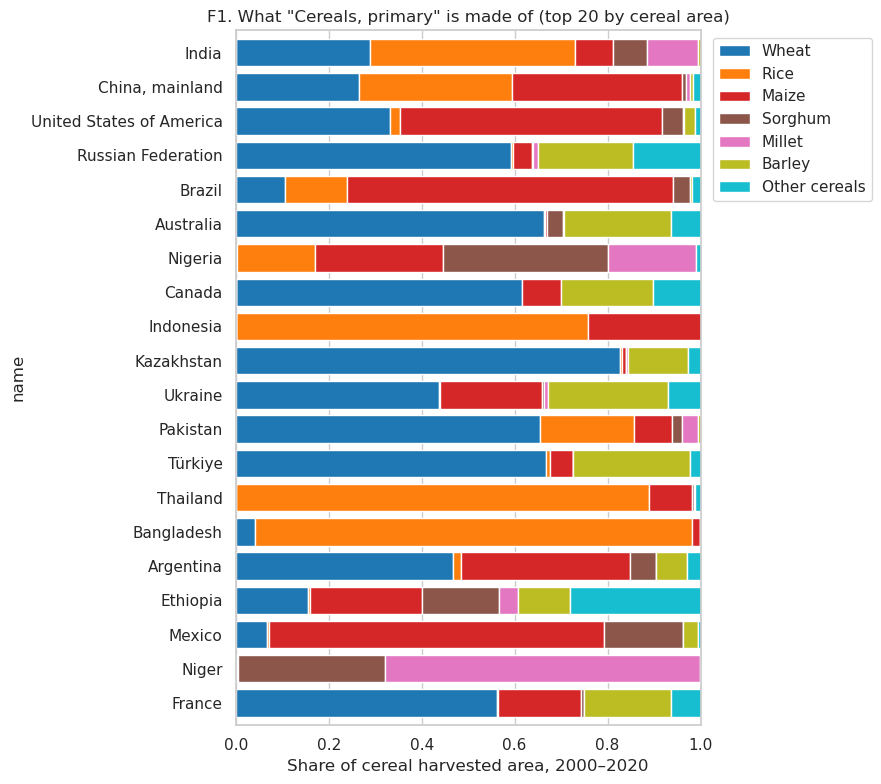

In [4]:
CEREAL_ITEMS = {15: 'Wheat', 27: 'Rice', 44: 'Barley', 56: 'Maize', 71: 'Rye', 75: 'Oats', 79: 'Millet',
                83: 'Sorghum', 89: 'Buckwheat', 92: 'Quinoa', 94: 'Fonio', 97: 'Triticale',
                101: 'Canary seed', 103: 'Mixed grain', 108: 'Cereals n.e.c.'}   # VERIFY against FAOSTAT definitions
print('Names in the file:', fao[fao['Item Code'].isin(CEREAL_ITEMS)][['Item Code', 'Item']]
      .drop_duplicates().sort_values('Item Code').values.tolist())

ah = fao[(fao['Element'] == 'Area harvested') & fao['iso3'].isin(STUDY) & fao['Year'].between(Y0, Y1)]
comp = (ah[ah['Item Code'].isin(CEREAL_ITEMS)]
        .pivot_table(index=['iso3', 'Year'], columns='Item Code', values='Value', aggfunc='sum', fill_value=0))
agg = ah[ah['Item Code'] == 1717].set_index(['iso3', 'Year'])['Value']
ratio = (comp.sum(axis=1) / agg).dropna()
print('Sum of component areas / "Cereals, primary" area:')
print(ratio.describe().round(3).to_string())

# Composition table and plot (top 20 cereal producers by area)
share = comp.groupby('iso3').sum()
share.columns = [CEREAL_ITEMS[c] for c in share.columns]
share = share.div(share.sum(axis=1), axis=0)
main_c = ['Wheat', 'Rice', 'Maize', 'Sorghum', 'Millet', 'Barley']
plot_share = share[main_c].copy()
plot_share['Other cereals'] = 1 - plot_share.sum(axis=1)
top = agg.groupby('iso3').mean().sort_values(ascending=False).head(20).index
ps = plot_share.loc[top]
ps.index = meta.set_index('iso3').loc[ps.index, 'name']
ps.plot(kind='barh', stacked=True, figsize=(9, 8), colormap='tab10', width=0.8)
plt.gca().invert_yaxis()
plt.xlabel('Share of cereal harvested area, 2000–2020')
plt.title('F1. What "Cereals, primary" is made of (top 20 by cereal area)')
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
savefig('F01_cereal_composition')
share.to_csv(f'{OUT}/cereal_composition.csv')

## Step 4 — Crop diversity over time (FAOSTAT)

In [5]:
print('Aggregate items excluded (check none is a real crop):',
      sorted(fao[(fao['Element'] == 'Area harvested') & (fao['Item Code'] >= 1700)]['Item'].unique()))
ahc = fao[(fao['Element'] == 'Area harvested') & (fao['Item Code'] < 1700)
          & fao['iso3'].isin(STUDY) & (fao['Value'] > 0)]
pv = ahc.pivot_table(index=['iso3', 'Year'], columns='Item Code', values='Value', aggfunc='sum', fill_value=0)
P = pv.div(pv.sum(axis=1), axis=0)
cdiv = pd.DataFrame({'crop_H': shannon_rows(pv),
                     'crop_simpson': 1 - (P ** 2).sum(axis=1),
                     'crop_rich': (pv > 0).sum(axis=1)}).reset_index().rename(columns={'Year': 'year'})
cdiv['crop_effN'] = np.exp(cdiv['crop_H'])
cdiv = cdiv.sort_values(['iso3', 'year'])
cdiv['crop_H_lag1'] = cdiv.groupby('iso3')['crop_H'].shift(1)
crop_H_base = cdiv[cdiv['year'].between(2000, 2004)].groupby('iso3')['crop_H'].mean().rename('crop_H_base')
cdiv.to_csv(f'{OUT}/crop_div_faostat.csv', index=False)
print(cdiv[['crop_H', 'crop_simpson', 'crop_rich', 'crop_effN']].describe().round(2))

Aggregate items excluded (check none is a real crop): ['Cereals, primary', 'Citrus Fruit, Total', 'Fibre Crops, Fibre Equivalent', 'Fruit Primary', 'Oilcrops, Cake Equivalent', 'Oilcrops, Oil Equivalent', 'Pulses, Total', 'Roots and Tubers, Total', 'Sugar Crops Primary', 'Treenuts, Total', 'Vegetables Primary']
        crop_H  crop_simpson  crop_rich  crop_effN
count  3123.00       3123.00    3123.00    3123.00
mean      2.19          0.78      52.32       9.90
std       0.48          0.12      20.42       4.49
min       0.45          0.16      10.00       1.57
25%       1.93          0.74      36.00       6.88
50%       2.21          0.81      52.00       9.14
75%       2.51          0.86      68.00      12.25
max       3.31          0.94     117.00      27.25


## Step 5 — Country boundaries (Natural Earth) and country masks on each grid

In [6]:
import geopandas as gpd
import rasterio
from rasterio import features as rfeat
from rasterio.transform import from_origin

ne = gpd.read_file(f'zip://{NE_ZIP}')

def _ne_iso(r):
    for c in ['ISO_A3_EH', 'ISO_A3', 'ADM0_A3']:
        v = r.get(c)
        if isinstance(v, str) and v not in ('-99', '-099'):
            return v
    return None

ne['iso3'] = ne.apply(_ne_iso, axis=1)
ne = ne[ne['iso3'].notna()].dissolve(by='iso3').reset_index()[['iso3', 'geometry']]
print('Natural Earth countries:', len(ne), '| study countries without a polygon:', sorted(set(STUDY) - set(ne['iso3'])))

ISO_ID = {iso: i + 1 for i, iso in enumerate(STUDY)}       # 0 = not a study country
ID_ISO = np.array(['NONE'] + STUDY)
_SHAPES = [(g, ISO_ID[i]) for i, g in zip(ne['iso3'], ne['geometry']) if i in ISO_ID]
_LABELS = {}

def label_grid(res):
    """Country id of every cell of a global grid with cell size `res` degrees (north-up, from -180/90)."""
    key = round(res, 6)
    if key not in _LABELS:
        h, w = int(round(180 / res)), int(round(360 / res))
        tr = from_origin(-180, 90, res, res)
        lab = rfeat.rasterize(_SHAPES, out_shape=(h, w), transform=tr, fill=0, dtype='int32')
        missing = set(ISO_ID.values()) - set(np.unique(lab))
        if missing:
            extra = rfeat.rasterize([(g, v) for g, v in _SHAPES if v in missing], out_shape=(h, w),
                                    transform=tr, fill=0, dtype='int32', all_touched=True)
            lab = np.where((lab == 0) & (extra > 0), extra, lab)
        _LABELS[key] = lab
    return _LABELS[key]

def by_country(lab, values):
    """Sum of `values` per study country (index = iso3)."""
    s = np.bincount(lab.ravel(), weights=np.nan_to_num(values).ravel(), minlength=len(ID_ISO))
    return pd.Series(s[1:], index=ID_ISO[1:])

def block_sum(a, f):
    h, w = a.shape
    return a[:h - h % f, :w - w % f].reshape(h // f, f, w // f, f).sum(axis=(1, 3))

def block_nanmean(a, f):
    h, w = a.shape
    with np.errstate(all='ignore'):
        return np.nanmean(a[:h - h % f, :w - w % f].reshape(h // f, f, w // f, f), axis=(1, 3))

lab5 = label_grid(1 / 12)
print('Countries found on the 5′ grid:', len(np.unique(lab5)) - 1, 'of', len(STUDY))

Natural Earth countries: 240 | study countries without a polygon: []
Countries found on the 5′ grid: 142 of 142


## Step 6 — MapSPAM 2020: crop diversity at five scales, irrigation share, and harvested-area weights

MapSPAM TA: /home/pranathi-sindhu/EST_final/data_downloads/spam2020V2r2_global_harvested_area.csv/spam2020V2r2_global_harvested_area/spam2020V2r2_global_H_TA.csv
MapSPAM cells with crops: 964,647 | crops: 46 | study countries found: 142 of 142
Study countries missing in MapSPAM: []
MapSPAM TI: /home/pranathi-sindhu/EST_final/data_downloads/spam2020V2r2_global_harvested_area.csv/spam2020V2r2_global_harvested_area/spam2020V2r2_global_H_TI.csv
                    count        mean       min           max
spam_H_cell         142.0        1.48      0.56  2.310000e+00
spam_H_0.25deg      142.0        1.63      0.65  2.460000e+00
spam_H_0.5deg       142.0        1.70      0.70  2.520000e+00
spam_H_1deg         142.0        1.77      0.70  2.580000e+00
spam_H_2deg         142.0        1.84      0.70  2.650000e+00
spam_H_nat          142.0        2.03      0.72  2.910000e+00
cereal_share        142.0        0.52      0.08  9.000000e-01
harvested_ha        142.0  9953377.00  60890.50  2.054631e+

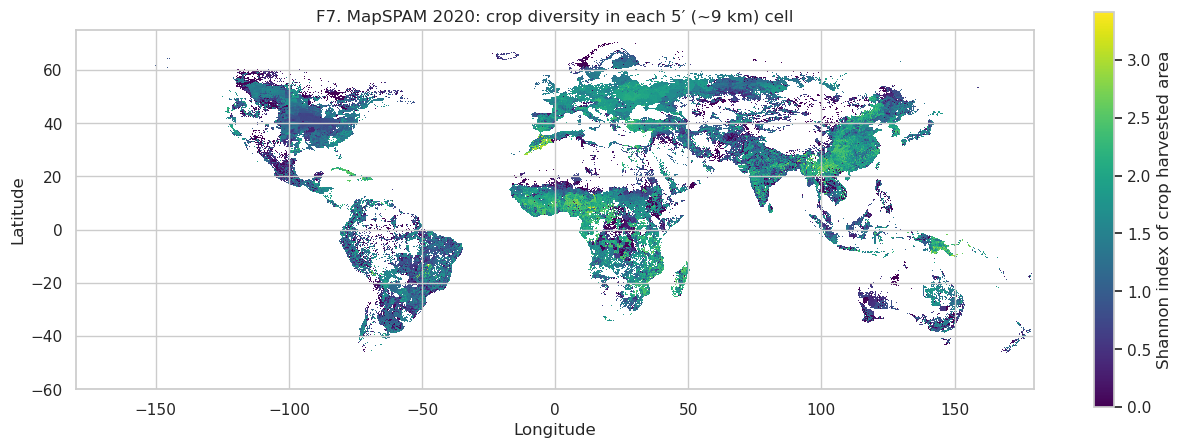

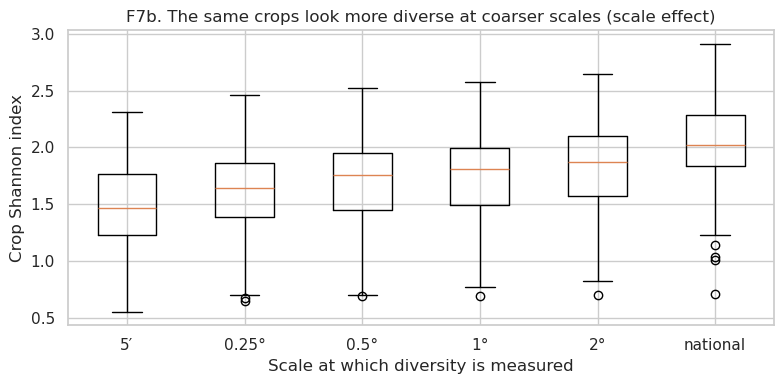

In [7]:
def spam_table(tag):
    """Find the MapSPAM harvested-area CSV for technology `tag` ('TA' = all, 'TI' = irrigated): loose file or inside a zip."""
    for root in (DATA, DATASETS):
        for f in sorted(glob.glob(os.path.join(root, '**', '*.csv'), recursive=True)):
            if 'spam' in f.lower() and re.search(rf'_H_{tag}\.csv$', f, re.I):
                return f, None
        for zf_ in sorted(glob.glob(os.path.join(root, '**', '*spam*.zip'), recursive=True)):
            for n in zipfile.ZipFile(zf_).namelist():
                if re.search(rf'_H_{tag}\.csv$', n, re.I):
                    return zf_, n
    return None, None

def read_spam_csv(tag):
    path, member = spam_table(tag)
    if path is None:
        return None
    print(f'MapSPAM {tag}:', path + (f' -> {member}' if member else ''))
    opener = (lambda: zipfile.ZipFile(path).open(member)) if member else (lambda: open(path, 'rb'))
    cols = pd.read_csv(opener(), nrows=0, encoding='latin-1').columns.tolist()
    start = [c.lower() for c in cols].index('whea')
    crop_cols = [c for c in cols[start:] if re.fullmatch(r'[a-z]{4}', c.lower())]
    parts = []
    for ch in pd.read_csv(opener(), usecols=['x', 'y', 'ADM0_NAME'] + crop_cols, chunksize=200_000, encoding='latin-1'):
        ch[crop_cols] = ch[crop_cols].apply(pd.to_numeric, errors='coerce').fillna(0).clip(lower=0).astype('float32')
        parts.append(ch)
    d = pd.concat(parts, ignore_index=True)
    d.columns = [c.lower() if c in crop_cols else c for c in d.columns]
    return d, [c.lower() for c in crop_cols]

ta, crop_cols = read_spam_csv('TA')
spam_names = ta['ADM0_NAME'].dropna().unique().tolist()
spam_iso = dict(zip(spam_names, to_iso3(spam_names)))
ta['iso3'] = ta['ADM0_NAME'].map(spam_iso)
ta['r'] = np.clip(np.floor((90 - ta['y']) * 12).astype(int), 0, 2159)
ta['c'] = np.clip(np.floor((ta['x'] + 180) * 12).astype(int), 0, 4319)
A = ta[crop_cols]
ta['tot'] = A.sum(axis=1)
ta = ta[ta['tot'] > 0].reset_index(drop=True)
A = ta[crop_cols]
ta['H_cell'] = shannon_rows(A).values
print(f'MapSPAM cells with crops: {len(ta):,} | crops: {len(crop_cols)} | study countries found:',
      ta.loc[ta['iso3'].isin(STUDY), 'iso3'].nunique(), 'of', len(STUDY))
print('Study countries missing in MapSPAM:', sorted(set(STUDY) - set(ta['iso3'])))

HARV_025 = np.zeros((720, 1440))                        # harvested ha per 0.25° cell -> climate weights (all countries)
np.add.at(HARV_025, (ta['r'].values // 3, ta['c'].values // 3), ta['tot'].values)
np.save(f'{CACHE}/harvested_ha_025.npy', HARV_025)

st = ta[ta['iso3'].isin(STUDY)]
As = st[crop_cols]
spam = pd.DataFrame({'spam_H_cell': (st['H_cell'] * st['tot']).groupby(st['iso3']).sum() / st['tot'].groupby(st['iso3']).sum()})
for name, f in [('0.25deg', 3), ('0.5deg', 6), ('1deg', 12), ('2deg', 24)]:
    g = As.groupby([st['iso3'], st['r'] // f, st['c'] // f]).sum()
    h, w = shannon_rows(g), g.sum(axis=1)
    spam[f'spam_H_{name}'] = (h * w).groupby(level=0).sum() / w.groupby(level=0).sum()
nat = As.groupby(st['iso3']).sum()
spam['spam_H_nat'] = shannon_rows(nat)
CEREALS_SPAM = [c for c in ['whea', 'rice', 'maiz', 'barl', 'mill', 'pmil', 'smil', 'sorg', 'ocer'] if c in crop_cols]
spam['cereal_share'] = nat[CEREALS_SPAM].sum(axis=1) / nat.sum(axis=1)
spam['harvested_ha'] = nat.sum(axis=1)

ti_res = read_spam_csv('TI')
if ti_res is not None:
    ti, _ = ti_res
    ti['iso3'] = ti['ADM0_NAME'].map(spam_iso)
    ti_nat = ti[ti['iso3'].isin(STUDY)].groupby('iso3')[crop_cols].sum()
    spam['irrig_share'] = ti_nat.sum(axis=1) / nat.sum(axis=1)
    spam['irrig_share_cereal'] = ti_nat[CEREALS_SPAM].sum(axis=1) / nat[CEREALS_SPAM].sum(axis=1)
    del ti
else:
    print('No irrigated (TI) file found: irrigation control will be skipped.')
spam = spam.replace([np.inf, -np.inf], np.nan).rename_axis('iso3').reset_index()
spam.to_csv(f'{OUT}/spam_diversity.csv', index=False)

SPAM_SCALES = ['spam_H_cell', 'spam_H_0.25deg', 'spam_H_0.5deg', 'spam_H_1deg', 'spam_H_2deg', 'spam_H_nat']
print(spam.drop(columns='iso3').describe().round(2).T[['count', 'mean', 'min', 'max']])
print('Spearman rank agreement across scales:')
print(spam[SPAM_SCALES].corr(method='spearman').round(2))

H_img = np.full((2160, 4320), np.nan, dtype='float32')
H_img[ta['r'].values, ta['c'].values] = ta['H_cell'].values
fig, ax = plt.subplots(figsize=(13, 6))
im = ax.imshow(H_img, extent=[-180, 180, -90, 90], cmap='viridis', interpolation='nearest')
plt.colorbar(im, ax=ax, label='Shannon index of crop harvested area', shrink=0.7)
ax.set_ylim(-60, 75)
ax.set_title('F7. MapSPAM 2020: crop diversity in each 5′ (~9 km) cell')
ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude')
savefig('F07_mapspam_cell_diversity')
del H_img

fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot([spam[c].dropna() for c in SPAM_SCALES])
ax.set_xticks(range(1, len(SPAM_SCALES) + 1), ['5′', '0.25°', '0.5°', '1°', '2°', 'national'])
ax.set_ylabel('Crop Shannon index'); ax.set_xlabel('Scale at which diversity is measured')
ax.set_title('F7b. The same crops look more diverse at coarser scales (scale effect)')
savefig('F07b_spam_scale_effect')

## Step 7 — Landscape / habitat diversity from FAOSTAT land use (yearly)

In [8]:
LU_URL = 'https://bulks-faostat.fao.org/production/Inputs_LandUse_E_All_Data_(Normalized).zip'   # VERIFY if the download fails
if LANDUSE_ZIP is None:
    target = os.path.join(DATA, 'Inputs_LandUse_E_All_Data_(Normalized).zip')
    try:
        import requests
        with requests.get(LU_URL, stream=True, timeout=120) as r:
            r.raise_for_status()
            with open(target, 'wb') as fh:
                for chunk in r.iter_content(1 << 20):
                    fh.write(chunk)
        zipfile.ZipFile(target).namelist()
        LANDUSE_ZIP = target
        print('Downloaded FAOSTAT land use ->', target)
    except Exception as e:
        if os.path.exists(target):
            os.remove(target)
        print('Could not download FAOSTAT land use:', str(e)[:100])

LU_VARS = ['landuse_H', 'natural_share', 'forest_share', 'irrig_lu']
if LANDUSE_ZIP:
    lu = read_fao_zip(LANDUSE_ZIP)
    lu = lu[lu['Element'].str.lower().eq('area')].merge(areas[['Area Code', 'iso3']], on='Area Code')
    items = {i.lower(): i for i in lu['Item'].unique()}
    LU_ITEMS = {'land': 'land area', 'cropland': 'cropland', 'arable': 'arable land', 'permcrop': 'permanent crops',
                'pasture': 'permanent meadows and pastures', 'forest': 'forest land', 'other': 'other land',
                'irrig': 'land area equipped for irrigation'}
    found = {k: items.get(v) for k, v in LU_ITEMS.items()}
    print('Land-use items matched (VERIFY):', found)
    lu = lu[lu['Item'].isin([v for v in found.values() if v])]
    lu['key'] = lu['Item'].map({v: k for k, v in found.items() if v})
    luw = lu.pivot_table(index=['iso3', 'Year'], columns='key', values='Value', aggfunc='sum').reset_index()
    luw = luw.rename(columns={'Year': 'year'})
    for c in ['arable', 'permcrop', 'pasture', 'forest', 'land', 'cropland', 'irrig', 'other']:
        if c not in luw:
            luw[c] = np.nan
    parts_ = ['arable', 'permcrop', 'pasture', 'forest']
    luw['other'] = luw['other'].fillna(luw['land'] - luw[parts_].fillna(0).sum(axis=1)).clip(lower=0)
    comp = luw[parts_ + ['other']].fillna(0)
    luw['landuse_H'] = shannon_rows(comp)
    luw.loc[comp.sum(axis=1) <= 0, 'landuse_H'] = np.nan
    luw['natural_share'] = (luw['forest'].fillna(0) + luw['pasture'].fillna(0)) / luw['land']
    luw['forest_share'] = luw['forest'] / luw['land']
    luw['irrig_lu'] = luw['irrig'] / luw['cropland']
    luw = luw[luw['iso3'].isin(STUDY)].sort_values(['iso3', 'year'])
    for c in LU_VARS:
        luw[f'{c}_lag1'] = luw.groupby('iso3')[c].shift(1)
    lu_base = (luw[luw['year'].between(2000, 2004)].groupby('iso3')[LU_VARS].mean()
               .rename(columns=lambda c: f'{c}_base').reset_index())
    print(luw[LU_VARS].describe().round(2))
    print('Countries with land-use data:', luw['iso3'].nunique(), 'of', len(STUDY))
else:
    print('Continuing WITHOUT land-use variables.')
    luw = pd.DataFrame(columns=['iso3', 'year'] + [f'{c}_lag1' for c in LU_VARS])
    lu_base = pd.DataFrame(columns=['iso3'] + [f'{c}_base' for c in LU_VARS])
luw.to_csv(f'{OUT}/landuse_diversity.csv', index=False)
LAND_MAIN = 'landuse_H_base'

# Land area of each country (km²) from the Natural Earth polygons (equal-area projection), used by GBIF effort
land_km2 = pd.Series(ne.set_index('iso3').to_crs('ESRI:54034').area.values / 1e6, index=ne['iso3'].values)

def have(df, cols):
    """Keep only columns that exist in df and contain data (so optional datasets can be missing)."""
    return [c for c in cols if c in df.columns and pd.to_numeric(df[c], errors='coerce').notna().any()]

Inputs_LandUse_E_All_Data_(Normalized).zip: Inputs_LandUse_E_All_Data_(Normalized).csv | encoding utf-8 | 163,266 rows
Land-use items matched (VERIFY): {'land': 'Land area', 'cropland': 'Cropland', 'arable': 'Arable land', 'permcrop': 'Permanent crops', 'pasture': 'Permanent meadows and pastures', 'forest': 'Forest land', 'other': 'Other land', 'irrig': 'Land area equipped for irrigation'}
key    landuse_H  natural_share  forest_share  irrig_lu
count    3123.00        3123.00       3101.00   3101.00
mean        1.14           0.56          0.32      0.23
std         0.27           0.21          0.22      0.27
min         0.16           0.00          0.00      0.00
25%         0.99           0.42          0.13      0.03
50%         1.18           0.56          0.30      0.11
75%         1.35           0.73          0.47      0.33
max         1.56           0.97          0.94      1.35
Countries with land-use data: 142 of 142


## Step 8 — Scale demonstration with real 10 m WorldCover data (one tile)

WorldCover tile read in 25 s, 100 m grid 3600x3600
     scale  mean_H  cropland_weighted_H   cells
     100 m   0.230                0.253 8251771
      1 km   0.599                0.861   82794
      5 km   0.805                1.141    3361
     10 km   0.878                1.254     858
whole tile   1.550                1.550       1
Tile composition: {'tree': 0.154, 'shrub': 0.0, 'grass': 0.244, 'crop': 0.152, 'built': 0.085, 'bare': 0.003, 'water': 0.355, 'wetland': 0.008}


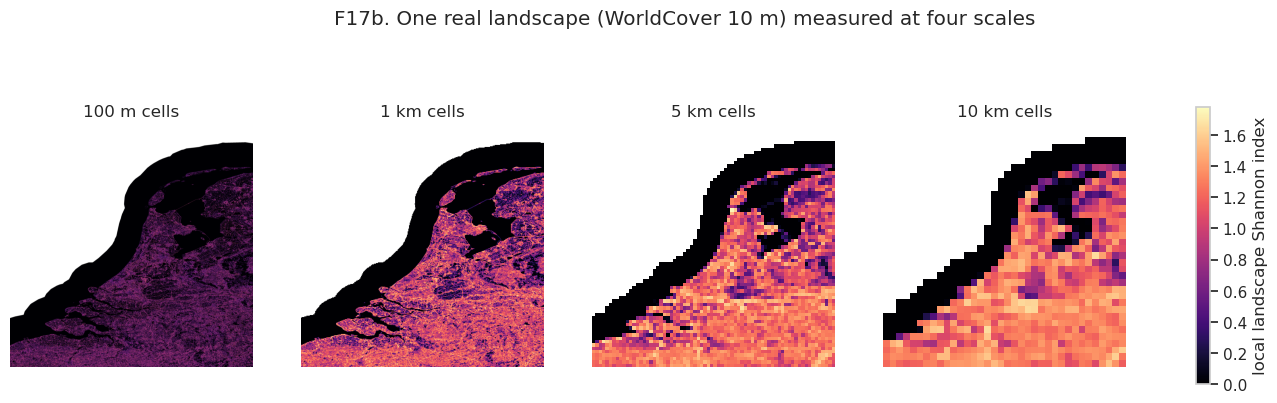

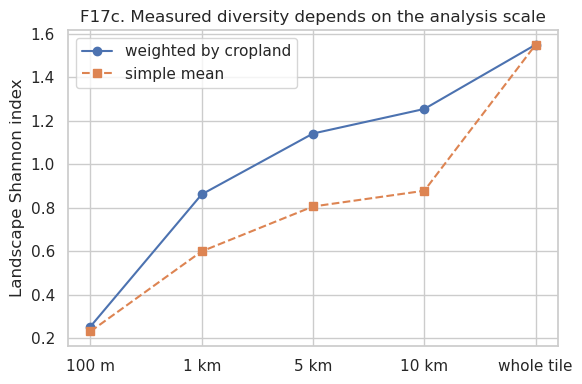

In [9]:
WC = {10: 'tree', 20: 'shrub', 30: 'grass', 40: 'crop', 50: 'built', 60: 'bare',
      70: 'snow', 80: 'water', 90: 'wetland', 95: 'mangrove', 100: 'moss'}
wc_demo = None
if WC_TIF:
    with rasterio.open(WC_TIF) as src:
        Hh, Ww = src.height - src.height % 1000, src.width - src.width % 1000
        counts = np.zeros((len(WC), Hh // 10, Ww // 10), dtype=np.uint8)      # class counts per 100 m block
        step = 1000
        t0 = time.time()
        for r0 in range(0, Hh, step):
            arr = src.read(1, window=rasterio.windows.Window(0, r0, Ww, step))
            for i, code in enumerate(WC):
                counts[i, r0 // 10:(r0 + step) // 10] = (arr == code).reshape(step // 10, 10, Ww // 10, 10).sum(axis=(1, 3))
        print(f'WorldCover tile read in {time.time() - t0:.0f} s, 100 m grid {counts.shape[1]}x{counts.shape[2]}')

    def local_H(cnt, rows=400):
        """Shannon index per cell from class counts (classes, y, x); processed in row chunks to save memory."""
        H = np.full(cnt.shape[1:], np.nan, dtype=np.float32)
        for r0 in range(0, cnt.shape[1], rows):
            c = cnt[:, r0:r0 + rows].astype(np.float32)
            tot = c.sum(axis=0)
            p = c / np.where(tot > 0, tot, 1)
            h = -(np.where(p > 0, p * np.log(np.where(p > 0, p, 1)), 0)).sum(axis=0)
            H[r0:r0 + rows] = np.where(tot > 0, h, np.nan)
        return H

    rows, maps = [], {}
    for name, f in [('100 m', 1), ('1 km', 10), ('5 km', 50), ('10 km', 100)]:
        cnt = counts if f == 1 else np.stack([block_sum(counts[i].astype(np.float32), f) for i in range(len(WC))])
        H = local_H(cnt)
        crop = cnt[list(WC).index(40)].astype(np.float64)
        rows.append({'scale': name, 'mean_H': np.nanmean(H),
                     'cropland_weighted_H': np.nansum(H * crop) / crop.sum() if crop.sum() > 0 else np.nan,
                     'cells': int(np.isfinite(H).sum())})
        maps[name] = H
    whole = counts.reshape(len(WC), -1).sum(axis=1).astype(float)
    pw = whole[whole > 0] / whole.sum()
    rows.append({'scale': 'whole tile', 'mean_H': -(pw * np.log(pw)).sum(),
                 'cropland_weighted_H': -(pw * np.log(pw)).sum(), 'cells': 1})
    wc_demo = pd.DataFrame(rows)
    wc_demo.to_csv(f'{OUT}/worldcover_scale_demo.csv', index=False)
    print(wc_demo.round(3).to_string(index=False))
    print('Tile composition:', {WC[c]: round(float(v / whole.sum()), 3) for c, v in zip(WC, whole) if v > 0})

    fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
    vmax = max(np.nanmax(H) for H in maps.values())
    for ax, (name, H) in zip(axes, maps.items()):
        im = ax.imshow(H, cmap='magma', vmin=0, vmax=vmax)
        ax.set_title(f'{name} cells'); ax.axis('off')
    plt.colorbar(im, ax=axes, label='local landscape Shannon index', shrink=0.8)
    fig.suptitle('F17b. One real landscape (WorldCover 10 m) measured at four scales', y=1.02)
    plt.savefig(f'{FIG}/F17b_worldcover_scales.png', dpi=200, bbox_inches='tight'); plt.show(); plt.close('all')

    plt.figure(figsize=(6, 4))
    plt.plot(wc_demo['scale'], wc_demo['cropland_weighted_H'], 'o-', label='weighted by cropland')
    plt.plot(wc_demo['scale'], wc_demo['mean_H'], 's--', label='simple mean')
    plt.ylabel('Landscape Shannon index'); plt.legend()
    plt.title('F17c. Measured diversity depends on the analysis scale')
    savefig('F17c_worldcover_scale_curve')
else:
    print('No WorldCover tile found, skipping the scale demonstration.')

## Step 9 — Climate from TerraClimate, harmonised to cropland

In [12]:
# Remove duplicate compressed files from data_downloads
for pattern in ['cru_ts*.pre.dat.nc.gz', 'cru_ts*.tmx.dat.nc.gz']:
    for f in glob.glob(os.path.join(DATA, pattern)):
        os.remove(f)
        print(f"Removed duplicate file: {os.path.basename(f)}")

Removed duplicate file: cru_ts4.07.1901.2022.pre.dat.nc.gz
Removed duplicate file: cru_ts4.07.1901.2022.tmx.dat.nc.gz


In [13]:
import xarray as xr

# Search only for uncompressed .nc files to avoid duplication
CRU_FILES = {
    v: sorted(
        set(glob.glob(os.path.join(DATA, f'cru_ts*.{v}.dat.nc')) + 
            glob.glob(os.path.join(CACHE, f'cru_ts*.{v}.dat.nc')))
    )
    for v in ('pre', 'tmx', 'tmp')
}

# Ignore .gz files if .nc uncompressed file exists
for v in CRU_FILES:
    CRU_FILES[v] = [f for f in CRU_FILES[v] if not f.endswith('.gz')]

USE_CRU = bool(CRU_FILES['pre']) and bool(CRU_FILES['tmx'] or CRU_FILES['tmp'])

if not USE_CRU:
    raise FileNotFoundError("No uncompressed CRU TS .nc files found in data_downloads/ or outputs/cache/!")

CLIM_TAG = 'cru'
CLIM_YEARS = list(range(Y0 - 1, Y1 + 1))  # 1999–2020

def clim_csv(year):
    return f'{CACHE}/clim_{CLIM_TAG}_{year}.csv'

def cru_open_sliced(var):
    """Open uncompressed CRU file and slice years 1999-2020 directly."""
    filepath = CRU_FILES[var][0]
    print(f"Loading {var}: {os.path.basename(filepath)}")
    da = xr.open_dataset(filepath)[var].sel(time=slice('1999-01-01', '2020-12-31'))
    if float(da.lat[0]) < float(da.lat[-1]):
        da = da.isel(lat=slice(None, None, -1))
    return da

tvar = 'tmx' if CRU_FILES['tmx'] else 'tmp'

# Load sliced DataArrays
pre_da = cru_open_sliced('pre')
tx_da = cru_open_sliced(tvar)

# Setup spatial masks and weights on 0.5° grid
HARV_025 = np.load(f'{CACHE}/harvested_ha_025.npy')
lab05 = label_grid(0.5)
H05 = block_sum(HARV_025, 2)
lat05 = 90 - 0.25 - 0.5 * np.arange(360)
area05 = np.repeat(np.cos(np.deg2rad(lat05))[:, None], 720, axis=1)
cell05 = area05 * (0.5 * 111.32) ** 2 * 100
W05 = {'u': area05, 'w': H05, 'm': area05 * (H05 / cell05 > 0.05)}

t0_all = time.time()
for y in CLIM_YEARS:
    if os.path.exists(clim_csv(y)):
        print(f'{y}: climate table already present, skipping.')
        continue

    p_y = pre_da.sel(time=str(y)).values.astype('float32')
    t_y = tx_da.sel(time=str(y)).values.astype('float32')

    if p_y.shape[0] != 12 or t_y.shape[0] != 12:
        print(f'{y}: shape {p_y.shape[0]} months (expected 12), skipping.')
        continue

    rows = []
    for mo in range(12):
        rec = {}
        for k, w in W05.items():
            for vn, a in {'precip': p_y[mo], 'tmax': t_y[mo], 'temp': t_y[mo]}.items():
                ok = np.isfinite(a)
                rec[f'{vn}_{k}'] = by_country(lab05, np.where(ok, a, 0) * w) / by_country(lab05, w * ok)
        df = pd.DataFrame(rec)
        df['year'], df['month'] = y, mo + 1
        rows.append(df.rename_axis('iso3').reset_index())

    pd.concat(rows, ignore_index=True).to_csv(clim_csv(y), index=False)
    print(f'{y}: climate table saved (CRU)', flush=True)

print(f'\nCRU TS processing completed in {(time.time() - t0_all):.1f} s.')

Loading pre: cru_ts4.07.1901.2022.pre.dat.nc
Loading tmx: cru_ts4.07.1901.2022.tmx.dat.nc
1999: climate table saved (CRU)
2000: climate table saved (CRU)
2001: climate table saved (CRU)
2002: climate table saved (CRU)
2003: climate table saved (CRU)
2004: climate table saved (CRU)
2005: climate table saved (CRU)
2006: climate table saved (CRU)
2007: climate table saved (CRU)
2008: climate table saved (CRU)
2009: climate table saved (CRU)
2010: climate table saved (CRU)
2011: climate table saved (CRU)
2012: climate table saved (CRU)
2013: climate table saved (CRU)
2014: climate table saved (CRU)
2015: climate table saved (CRU)
2016: climate table saved (CRU)
2017: climate table saved (CRU)
2018: climate table saved (CRU)
2019: climate table saved (CRU)
2020: climate table saved (CRU)

CRU TS processing completed in 14.3 s.


## Step 10 — Climate features (growing season, anomalies, stress counts)

In [16]:
# Determine the climate tag used in Step 9
CLIM_TAG = globals().get('CLIM_TAG', globals().get('TC_METHOD', 'cru'))
CLIM_YEARS = list(range(Y0 - 1, Y1 + 1))  # 1999–2020

# Load all generated climate CSV files
clim_files = [f'{CACHE}/clim_{CLIM_TAG}_{y}.csv' for y in CLIM_YEARS if os.path.exists(f'{CACHE}/clim_{CLIM_TAG}_{y}.csv')]

if not clim_files:
    raise FileNotFoundError(f"No climate CSVs found in {CACHE} with tag '{CLIM_TAG}'. Please re-run Step 9.")

cl = pd.concat([pd.read_csv(f) for f in clim_files], ignore_index=True)
print('Climate years loaded:', cl['year'].nunique(), '| countries:', cl['iso3'].nunique())
missing_years = sorted(set(CLIM_YEARS) - set(cl['year']))
if missing_years:
    print('WARNING: missing climate years', missing_years, '- re-run Step 9 to complete them.')

def monthly(k):
    return pd.DataFrame({'iso3': cl['iso3'], 'year': cl['year'], 'month': cl['month'],
                         'precip': cl[f'precip_{k}'], 'temp': cl[f'temp_{k}'], 'tmax': cl[f'tmax_{k}']})

def zs(x):
    return (x - x.mean()) / x.std()

def season_features(cm):
    out, starts = [], {}
    for iso, g in cm.dropna(subset=['precip']).groupby('iso3'):
        g = g.copy()
        clim_m = g[g['year'].between(Y0, Y1)].groupby('month')['precip'].mean().reindex(range(1, 13))
        if clim_m.isna().any():
            continue
        s = max(range(1, 13), key=lambda st: sum(clim_m[(st - 1 + k) % 12 + 1] for k in range(4)))
        months = [(s - 1 + k) % 12 + 1 for k in range(4)]
        starts[iso] = s
        g['q20'] = g.groupby('month')['precip'].transform(lambda x: x.quantile(.2))
        g['q80'] = g.groupby('month')['temp'].transform(lambda x: x.quantile(.8))
        g['dry'] = (g['precip'] < g['q20']).astype(int)
        g['hot'] = (g['temp'] > g['q80']).astype(int)
        h = g[g['month'].isin(months)].copy()
        h['hy'] = np.where(h['month'] > months[-1], h['year'] + 1, h['year'])     # harvest year
        a = h.groupby('hy').agg(rain=('precip', 'sum'), temp=('temp', 'mean'), tmax=('tmax', 'max'),
                                dry_months=('dry', 'sum'), hot_months=('hot', 'sum'), n=('month', 'size'))
        a = a[(a['n'] == 4) & (a.index >= Y0) & (a.index <= Y1)].drop(columns='n')
        ann = g.groupby('year').agg(rain_ann=('precip', 'sum'), temp_ann=('temp', 'mean'))
        a = a.join(ann, how='left')
        a['rain_z'], a['heat_z'], a['tmax_z'] = zs(a['rain']), zs(a['temp']), zs(a['tmax'])
        a['rain_ann_z'], a['heat_ann_z'] = zs(a['rain_ann']), zs(a['temp_ann'])
        a['iso3'] = iso
        out.append(a.rename_axis('year').reset_index())
    return pd.concat(out, ignore_index=True), starts

feats, season_start = season_features(monthly('w'))
for k in 'um':
    fk, _ = season_features(monthly(k))
    feats = feats.merge(fk[['iso3', 'year', 'rain_z', 'heat_z']].rename(
        columns={'rain_z': f'rain_z_{k}', 'heat_z': f'heat_z_{k}'}), on=['iso3', 'year'], how='left')
feats['drought'] = (feats['rain_z'] < -1).astype(int)
feats['heatwave'] = (feats['heat_z'] > 1).astype(int)
feats.to_csv(f'{OUT}/climate_features.csv', index=False)
cl.to_csv(f'{OUT}/climate_monthly_all.csv', index=False)
print(feats.shape, '| countries:', feats['iso3'].nunique())
print('Correlation, harvested-area-weighted vs whole-country rain_z:', round(feats['rain_z'].corr(feats['rain_z_u']), 3),
      '| heat_z:', round(feats['heat_z'].corr(feats['heat_z_u']), 3))

Climate years loaded: 22 | countries: 142
(2982, 20) | countries: 142
Correlation, harvested-area-weighted vs whole-country rain_z: 0.881 | heat_z: 0.917


## Step 11 — GBIF habitat biodiversity (birds), corrected for sampling effort

In [19]:
import requests
from scipy.special import gammaln

GBIF = 'https://api.gbif.org/v1'
CLASS_KEY = 212
print('classKey', CLASS_KEY, '=', requests.get(f'{GBIF}/species/{CLASS_KEY}', timeout=30).json().get('scientificName'))

def gbif_counts(iso2, page=1000, max_pages=30):
    counts, off, total = {}, 0, 0
    for _ in range(max_pages):
        r = requests.get(f'{GBIF}/occurrence/search', timeout=90, params={
            'country': iso2, 'classKey': CLASS_KEY, 'year': f'{Y0},{Y1}', 'limit': 0,
            'facet': 'speciesKey', 'facetLimit': page, 'facetOffset': off}).json()
        total = r.get('count', 0)
        f = r['facets'][0]['counts'] if r.get('facets') else []
        counts.update({c['name']: c['count'] for c in f})
        if len(f) < page:
            break
        off += page
        time.sleep(0.2)
    return total, np.array(list(counts.values()), dtype=float)

def rarefy(counts, n):
    N = counts.sum()
    if N < n:
        return np.nan
    logC = lambda a, b: gammaln(a + 1) - gammaln(b + 1) - gammaln(a - b + 1)
    rest = N - counts
    p_absent = np.where(rest >= n, np.exp(logC(np.maximum(rest, n), n) - logC(N, n)), 0.0)
    return float(np.sum(1 - p_absent))

GBIF_CACHE = f'{OUT}/gbif_birds.csv'
if os.path.exists(GBIF_CACHE):
    gb = pd.read_csv(GBIF_CACHE, keep_default_na=False, na_values=[''])
else:
    RARE_N = 5000
    rows = []
    for _, r in meta.iterrows():
        try:
            total, cnt = gbif_counts(r['iso2'])
            rows.append({'iso3': r['iso3'], 'gbif_records': total, 'gbif_species': len(cnt),
                         'bird_rich_rare': rarefy(cnt, RARE_N)})
        except Exception as e:
            print(r['iso3'], 'GBIF failed:', str(e)[:80])
    gb = pd.DataFrame(rows)
    gb.to_csv(GBIF_CACHE, index=False)
gb['land_area_km2'] = gb['iso3'].map(land_km2)
gb['gbif_effort'] = gb['gbif_records'] / gb['land_area_km2'] * 1000
print(gb.describe().round(1).T[['count', 'mean', 'min', 'max']])
print('Raw vs rarefied richness, Spearman with effort:',
      round(gb['gbif_species'].corr(gb['gbif_effort'], method='spearman'), 2), 'vs',
      round(gb['bird_rich_rare'].corr(gb['gbif_effort'], method='spearman'), 2))

classKey 212 = Aves
                count       mean      min          max
gbif_records    142.0  8232252.4   2859.0  580278670.0
gbif_species    142.0      668.0    207.0       2137.0
bird_rich_rare  137.0      400.1    170.9       1043.5
land_area_km2   142.0   898114.7  10007.8   16973513.4
gbif_effort     142.0    26563.9      3.1     927686.8
Raw vs rarefied richness, Spearman with effort: 0.32 vs -0.14


## Step 12 — Build the master panel and check data quality

Rows per crop: {'cereals': 2982, 'maize': 2268, 'rice': 1680, 'wheat': 1785}


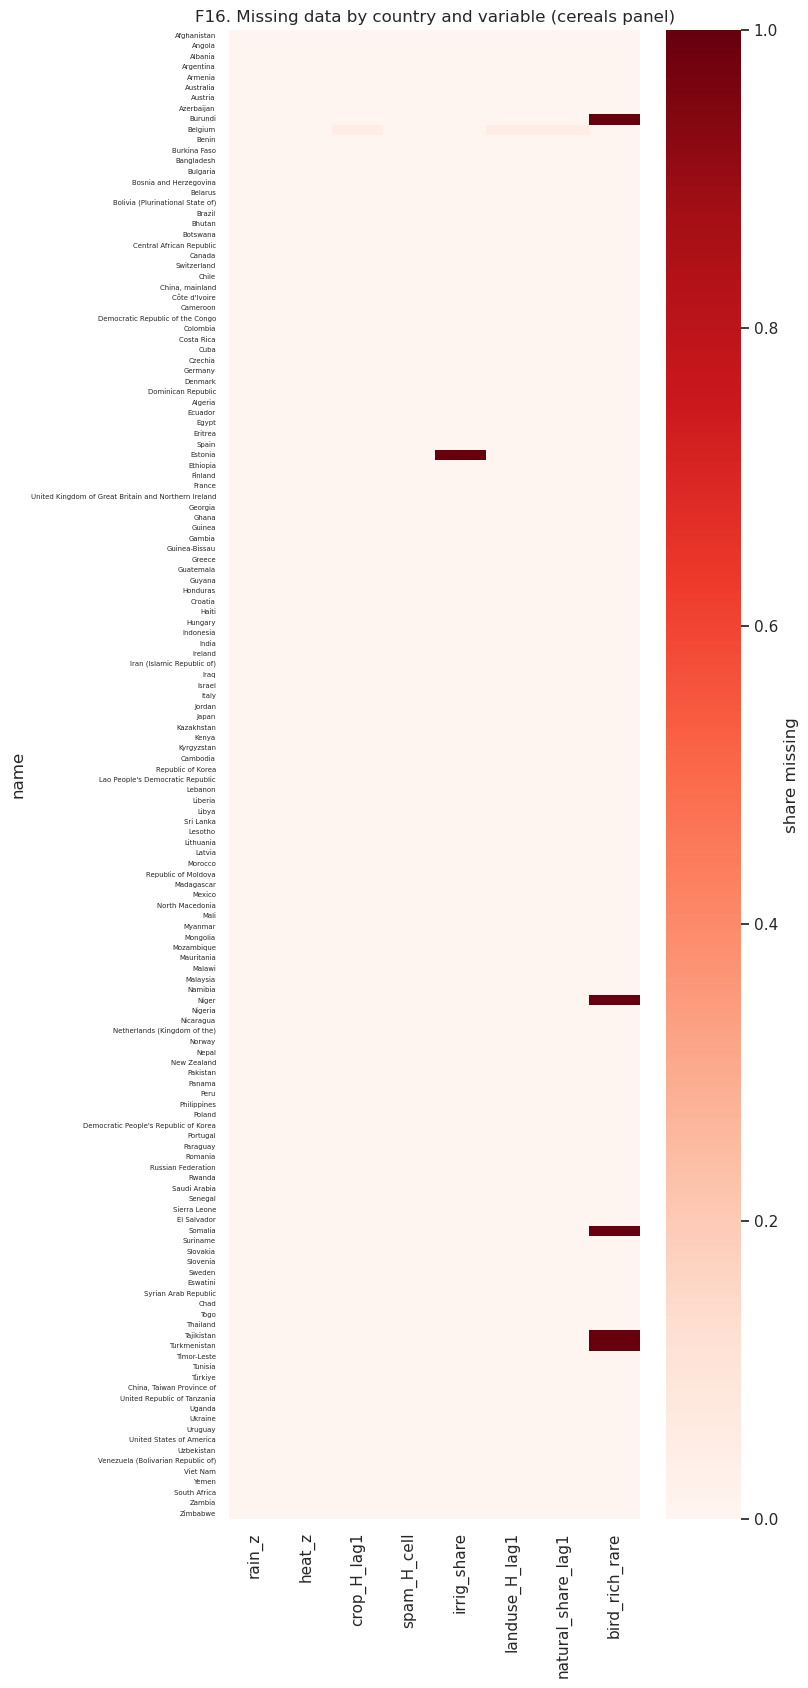

Share missing per variable:
rain_z                0.000
heat_z                0.000
crop_H_lag1           0.000
spam_H_cell           0.000
irrig_share           0.007
landuse_H_lag1        0.000
natural_share_lag1    0.000
bird_rich_rare        0.035


In [20]:
static = (meta.merge(spam, on='iso3', how='left')
          .merge(lu_base, on='iso3', how='left')
          .merge(gb[['iso3', 'bird_rich_rare', 'gbif_effort', 'gbif_species']], on='iso3', how='left')
          .merge(crop_H_base.reset_index(), on='iso3', how='left'))
pan = (yp.merge(feats, on=['iso3', 'year'], how='left')
       .merge(cdiv[['iso3', 'year', 'crop_H', 'crop_H_lag1', 'crop_effN']], on=['iso3', 'year'], how='left')
       .merge(luw[['iso3', 'year'] + [f'{c}_lag1' for c in LU_VARS]].astype({'year': int}), on=['iso3', 'year'], how='left')
       .merge(static, on='iso3', how='left')
       .merge(instab[['iso3', 'crop', 'mean_yield']], on=['iso3', 'crop'], how='left'))
pan['log_mean_yield'] = np.log(pan['mean_yield'])
pan.to_csv(f'{OUT}/master_panel.csv', index=False)
static.to_csv(f'{OUT}/country_static.csv', index=False)

print('Rows per crop:', pan.groupby('crop').size().to_dict())
QA_COLS = ['rain_z', 'heat_z', 'crop_H_lag1', 'spam_H_cell', 'irrig_share', 'landuse_H_lag1',
           'natural_share_lag1', 'bird_rich_rare']
QA_COLS = [c for c in QA_COLS if c in pan.columns]
c0 = pan[pan['crop'] == 'cereals']
miss = c0.groupby('iso3')[QA_COLS].apply(lambda d: d.isna().mean())
miss.index = meta.set_index('iso3').loc[miss.index, 'name']
plt.figure(figsize=(8, max(6, len(miss) * 0.12)))
sns.heatmap(miss, cmap='Reds', vmin=0, vmax=1, cbar_kws={'label': 'share missing'}, yticklabels=True)
plt.yticks(fontsize=5); plt.title('F16. Missing data by country and variable (cereals panel)')
savefig('F16_missing_data')
print('Share missing per variable:'); print(c0[QA_COLS].isna().mean().round(3).to_string())

## Step 13 — Exploratory plots 

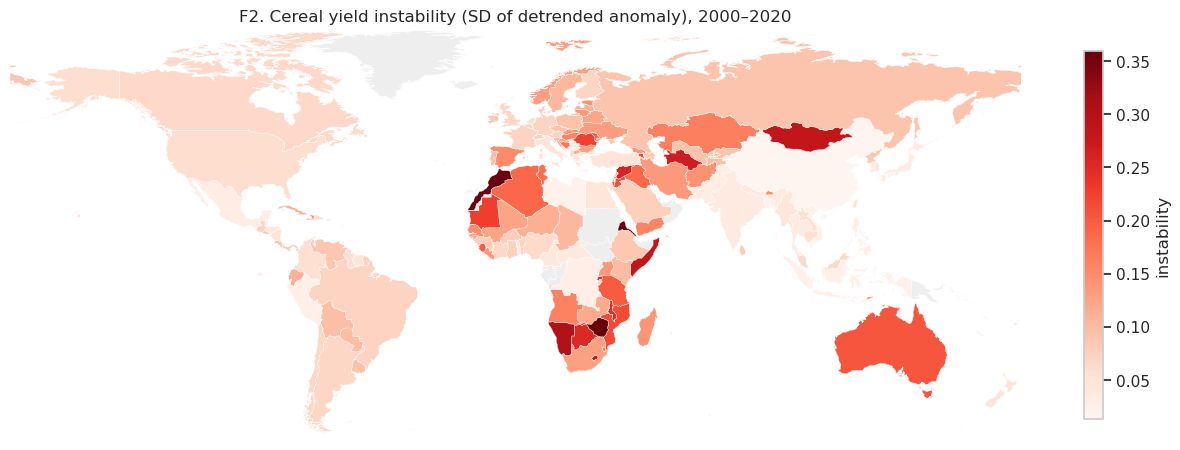

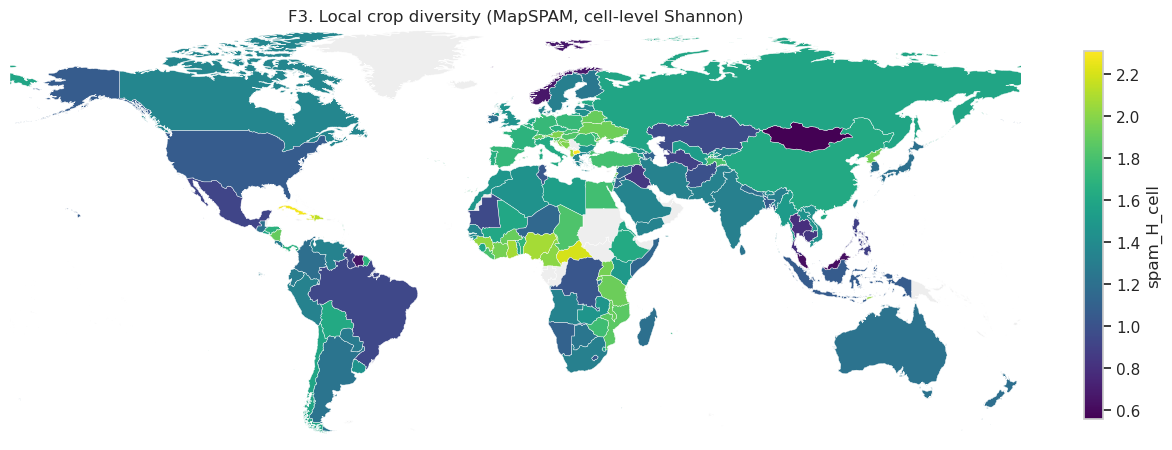

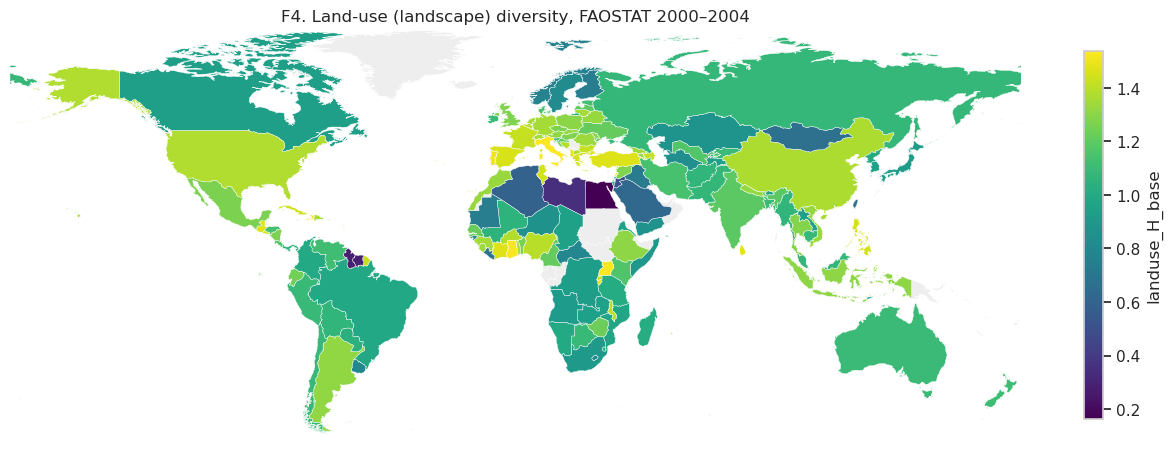

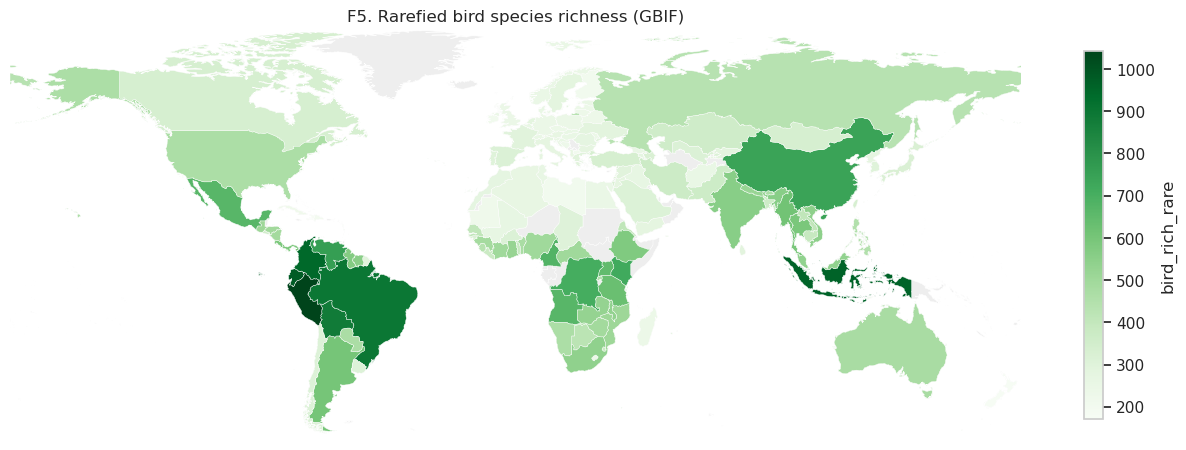

In [21]:
def world_map(df, col, title, fname, cmap='viridis'):
    g = ne.merge(df[['iso3', col]], on='iso3', how='left')
    fig, ax = plt.subplots(figsize=(13, 6.5))
    ne.plot(ax=ax, color='#eeeeee', edgecolor='white', linewidth=0.3)
    g.dropna(subset=[col]).plot(column=col, ax=ax, cmap=cmap, legend=True, edgecolor='white', linewidth=0.3,
                                legend_kwds={'shrink': 0.6, 'label': col})
    ax.set_xlim(-180, 180); ax.set_ylim(-58, 84); ax.axis('off')
    ax.set_title(title)
    savefig(fname)

cs = static.merge(instab[instab['crop'] == 'cereals'][['iso3', 'instability']], on='iso3', how='left')
world_map(cs, 'instability', 'F2. Cereal yield instability (SD of detrended anomaly), 2000–2020', 'F02_map_instability', 'Reds')
world_map(cs, 'spam_H_cell', 'F3. Local crop diversity (MapSPAM, cell-level Shannon)', 'F03_map_crop_div')
if have(cs, [LAND_MAIN]):
    world_map(cs, LAND_MAIN, 'F4. Land-use (landscape) diversity, FAOSTAT 2000–2004', 'F04_map_land_div')
world_map(cs, 'bird_rich_rare', 'F5. Rarefied bird species richness (GBIF)', 'F05_map_birds', 'Greens')

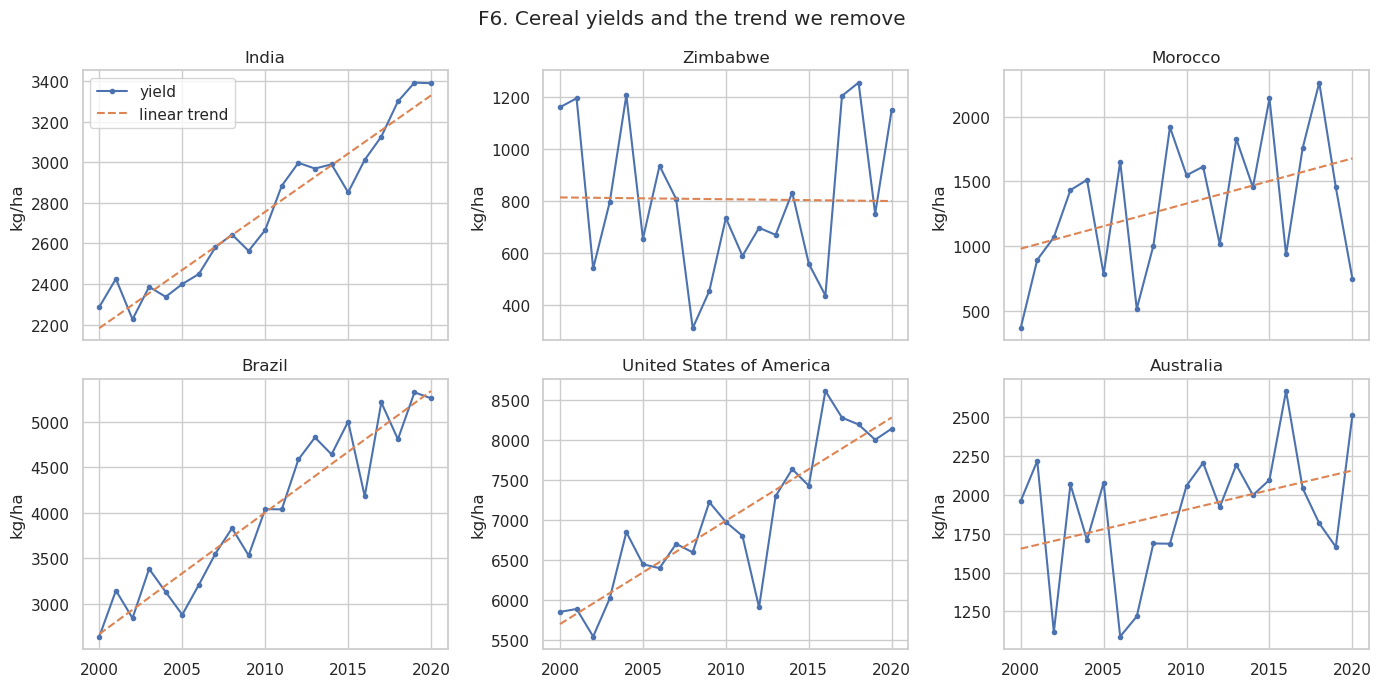

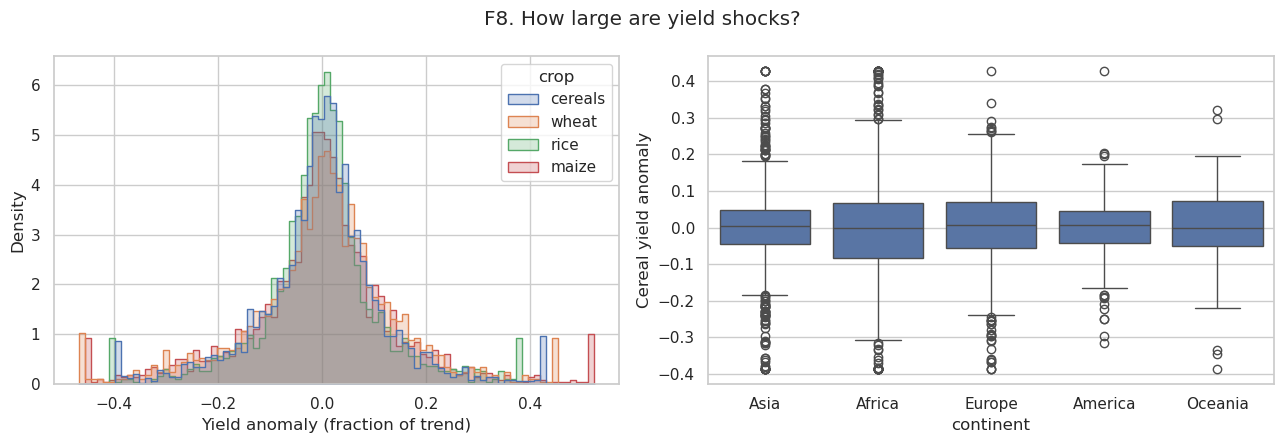

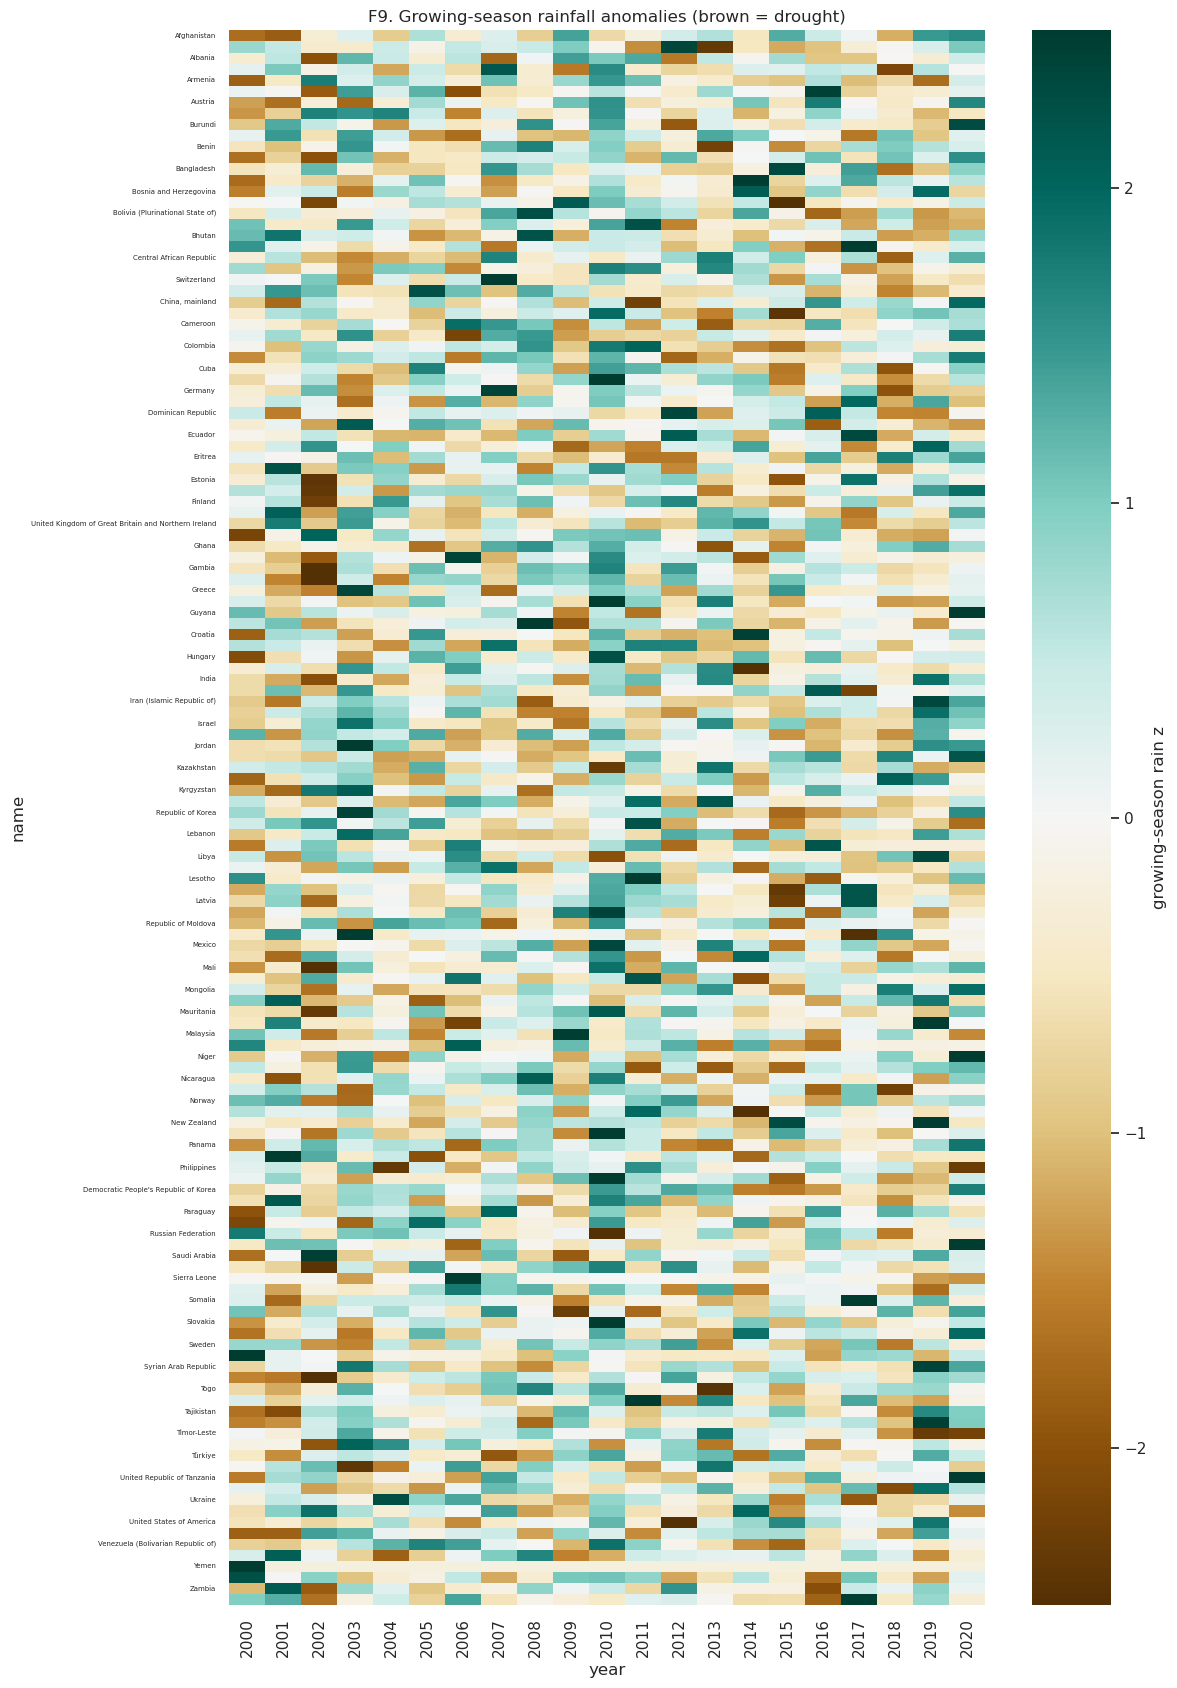

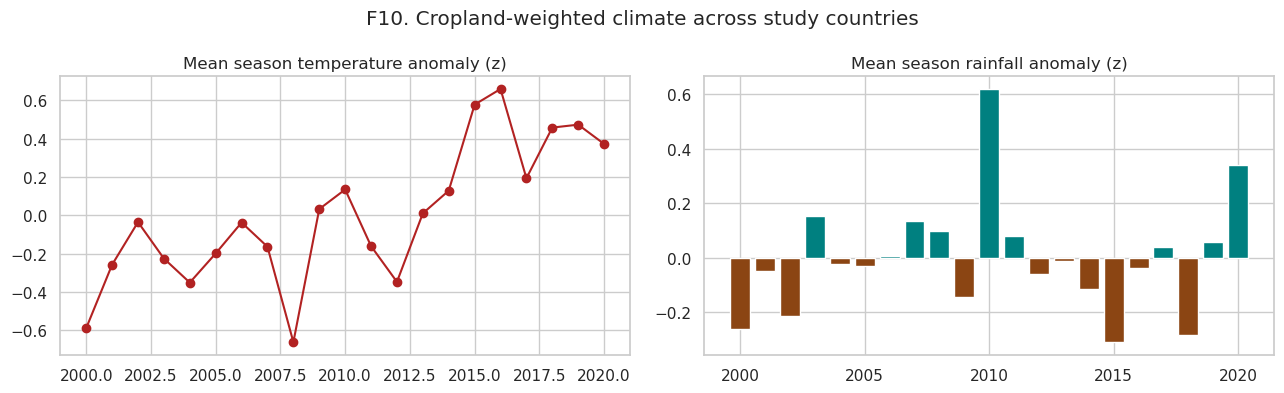

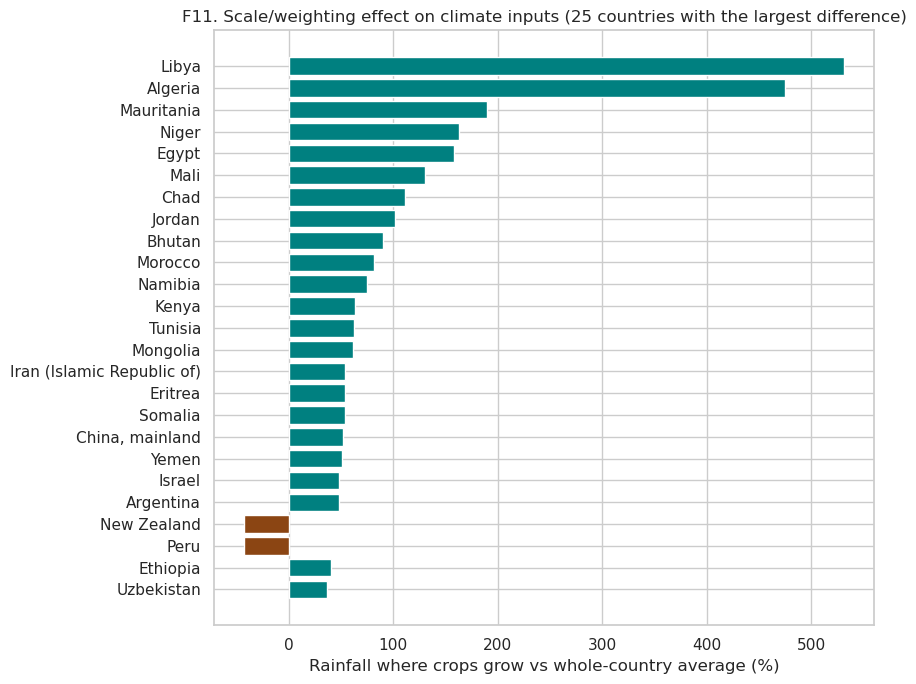

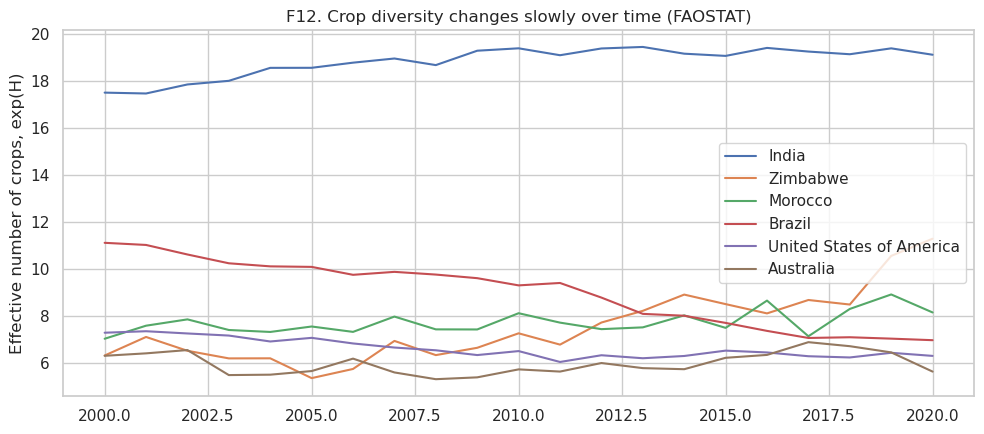

In [22]:
# F6. Yield series with trend for example countries
ex = [i for i in ['IND', 'ZWE', 'MAR', 'BRA', 'USA', 'AUS', 'NER', 'CHN'] if i in STUDY][:6]
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True)
for ax, iso in zip(axes.flat, ex):
    d = yp[(yp['iso3'] == iso) & (yp['crop'] == 'cereals')]
    ax.plot(d['year'], d['yield'], 'o-', ms=3, label='yield')
    ax.plot(d['year'], d['trend'], '--', label='linear trend')
    ax.set_title(meta.set_index('iso3').loc[iso, 'name'])
    ax.set_ylabel('kg/ha')
axes.flat[0].legend()
fig.suptitle('F6. Cereal yields and the trend we remove')
savefig('F06_yield_series')

# F8. Distribution of anomalies
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(data=pan, x='anom_w', hue='crop', element='step', stat='density', common_norm=False, ax=axes[0])
axes[0].set_xlabel('Yield anomaly (fraction of trend)')
sns.boxplot(data=pan[pan['crop'] == 'cereals'], x='continent', y='anom_w', ax=axes[1])
axes[1].set_ylabel('Cereal yield anomaly')
fig.suptitle('F8. How large are yield shocks?')
savefig('F08_anomaly_distribution')

# F9. Rainfall anomaly heatmap (country x year)
hm = feats.pivot_table(index='iso3', columns='year', values='rain_z')
hm.index = meta.set_index('iso3').loc[hm.index, 'name']
plt.figure(figsize=(12, max(6, len(hm) * 0.12)))
sns.heatmap(hm, cmap='BrBG', center=0, vmin=-2.5, vmax=2.5, cbar_kws={'label': 'growing-season rain z'})
plt.yticks(fontsize=5); plt.title('F9. Growing-season rainfall anomalies (brown = drought)')
savefig('F09_rain_heatmap')

# F10. Climate trends
tr = feats.groupby('year')[['temp', 'rain_z', 'heat_z']].mean()
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(tr.index, tr['heat_z'], 'o-', color='firebrick'); ax[0].set_title('Mean season temperature anomaly (z)')
ax[1].bar(tr.index, tr['rain_z'], color=np.where(tr['rain_z'] < 0, 'saddlebrown', 'teal'))
ax[1].set_title('Mean season rainfall anomaly (z)')
fig.suptitle('F10. Cropland-weighted climate across study countries')
savefig('F10_climate_trends')

# F11. Why harvested-area weighting matters: annual rainfall, whole country vs where crops grow
an = (cl[cl['year'].between(Y0, Y1)].groupby(['iso3', 'year'])[['precip_u', 'precip_w']].sum(min_count=12)
      .groupby('iso3').mean().dropna())
an['diff_pct'] = (an['precip_w'] / an['precip_u'] - 1) * 100
top = an.reindex(an['diff_pct'].abs().sort_values(ascending=False).index).head(25)
plt.figure(figsize=(9, 7))
plt.barh([NAME.get(i, i) for i in top.index], top['diff_pct'], color=np.where(top['diff_pct'] > 0, 'teal', 'saddlebrown'))
plt.gca().invert_yaxis()
plt.xlabel('Rainfall where crops grow vs whole-country average (%)')
plt.title('F11. Scale/weighting effect on climate inputs (25 countries with the largest difference)')
savefig('F11_weighting_effect')

# F12. Crop diversity trends over time (FAOSTAT)
plt.figure(figsize=(10, 4.5))
for iso in ex:
    d = cdiv[(cdiv['iso3'] == iso) & cdiv['year'].between(Y0, Y1)]
    plt.plot(d['year'], d['crop_effN'], label=meta.set_index('iso3').loc[iso, 'name'])
plt.ylabel('Effective number of crops, exp(H)'); plt.legend()
plt.title('F12. Crop diversity changes slowly over time (FAOSTAT)')
savefig('F12_crop_div_trends')

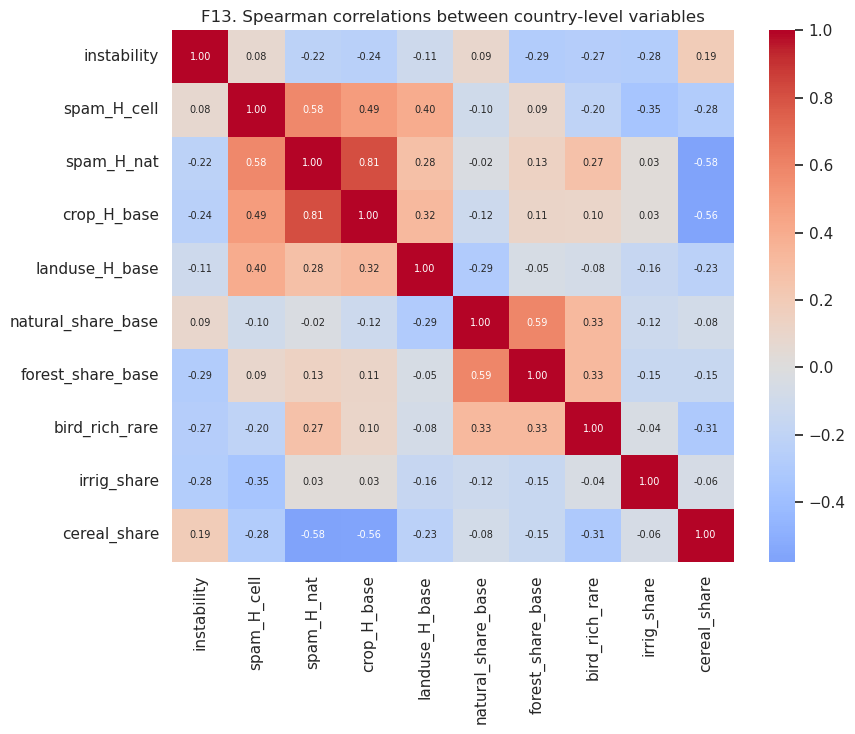

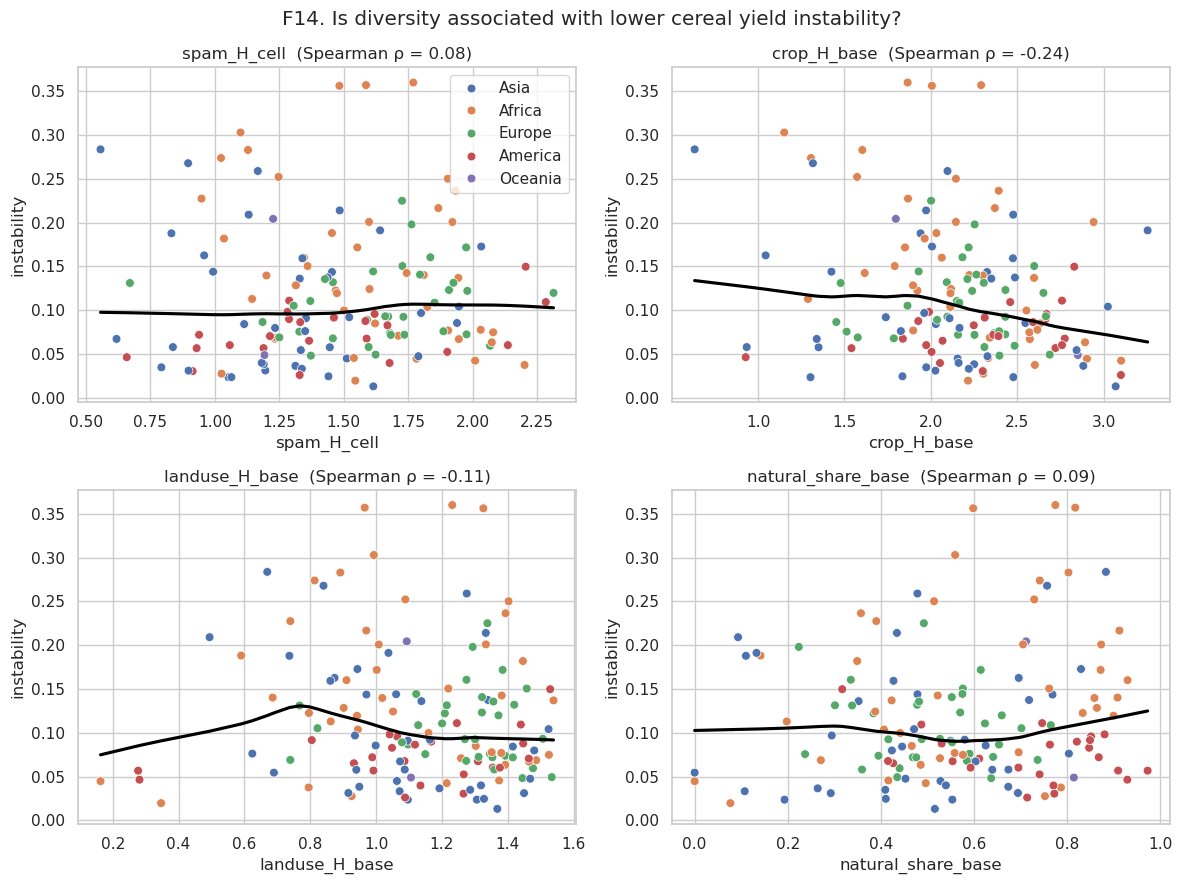

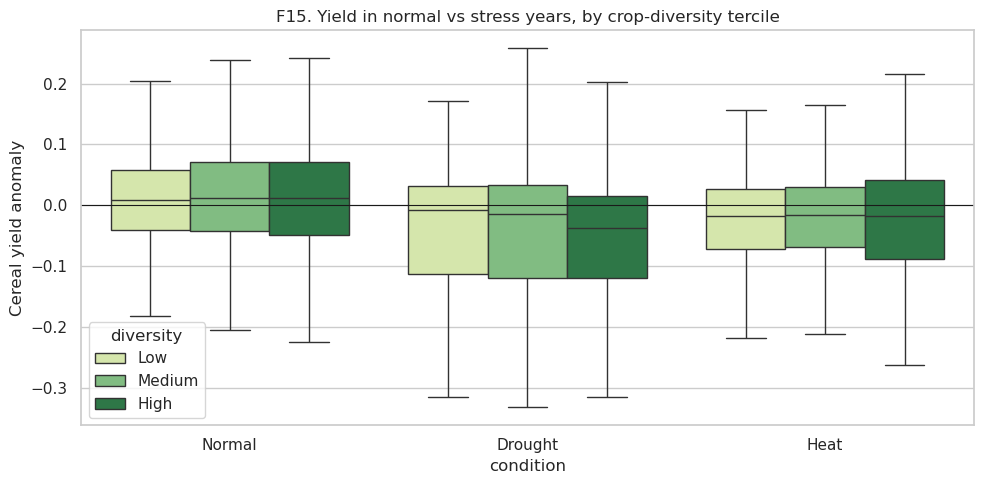

                      mean  median  size
condition diversity                     
Drought   Low       -0.044  -0.008   150
          Medium    -0.041  -0.015   148
          High      -0.055  -0.037   154
Heat      Low       -0.026  -0.017   117
          Medium    -0.029  -0.016   108
          High      -0.024  -0.018   112
Normal    Low        0.012   0.008   741
          Medium     0.014   0.011   731
          High       0.015   0.013   721


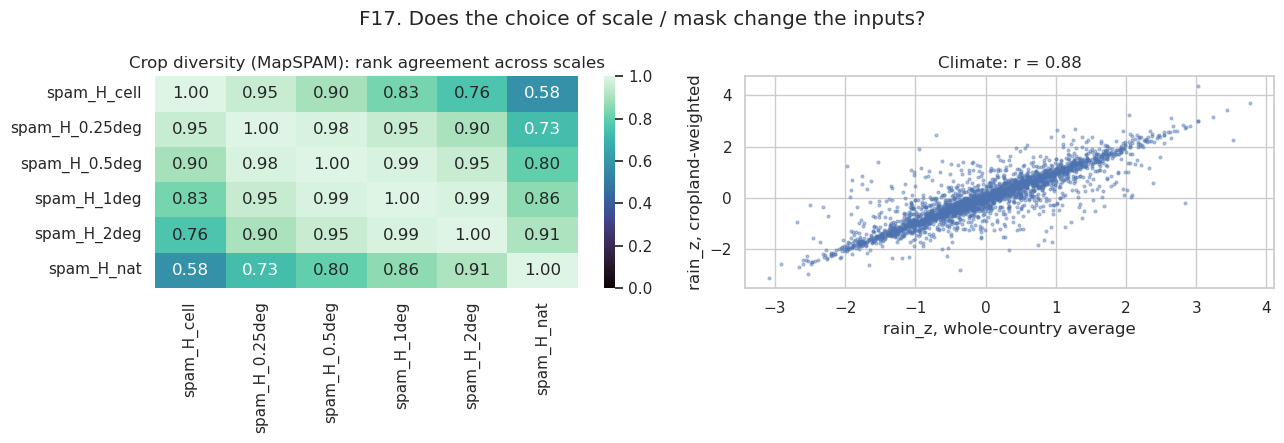

In [23]:
# F13. Correlation heatmap
CORR_COLS = ['instability', 'spam_H_cell', 'spam_H_nat', 'crop_H_base', 'landuse_H_base', 'natural_share_base',
             'forest_share_base', 'bird_rich_rare', 'irrig_share', 'cereal_share']
CORR_COLS = have(cs, CORR_COLS)
plt.figure(figsize=(9, 7.5))
sns.heatmap(cs[CORR_COLS].corr(method='spearman'), annot=True, fmt='.2f', cmap='coolwarm', center=0, annot_kws={'size': 7})
plt.title('F13. Spearman correlations between country-level variables')
savefig('F13_correlation_heatmap')

# F14. Diversity vs instability
DIV_PLOT = (have(cs, ['spam_H_cell', 'crop_H_base', 'landuse_H_base', 'natural_share_base', 'spam_H_nat', 'bird_rich_rare']))[:4]
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, col in zip(axes.flat, DIV_PLOT):
    sns.scatterplot(data=cs, x=col, y='instability', hue='continent', ax=ax, s=40)
    sns.regplot(data=cs, x=col, y='instability', scatter=False, ax=ax, color='black', lowess=True)
    rho = cs[[col, 'instability']].corr(method='spearman').iloc[0, 1]
    ax.set_title(f'{col}  (Spearman ρ = {rho:.2f})')
    ax.legend().set_visible(ax is axes.flat[0])
fig.suptitle('F14. Is diversity associated with lower cereal yield instability?')
savefig('F14_diversity_vs_instability')

# F15. The core picture: yield drop in drought/heat years by diversity tercile
c0 = pan[pan['crop'] == 'cereals'].copy()
c0['condition'] = np.select([c0['rain_z'] < -1, c0['heat_z'] > 1], ['Drought', 'Heat'], 'Normal')
c0['diversity'] = pd.qcut(c0['spam_H_cell'], 3, labels=['Low', 'Medium', 'High'])
plt.figure(figsize=(10, 5))
sns.boxplot(data=c0.dropna(subset=['diversity']), x='condition', y='anom_w', hue='diversity',
            order=['Normal', 'Drought', 'Heat'], palette='YlGn', showfliers=False)
plt.axhline(0, color='k', lw=0.8)
plt.ylabel('Cereal yield anomaly'); plt.title('F15. Yield in normal vs stress years, by crop-diversity tercile')
savefig('F15_stress_by_diversity')
print(c0.groupby(['condition', 'diversity'], observed=True)['anom_w'].agg(['mean', 'median', 'size']).round(3))

# F17. Scale sensitivity summary
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.heatmap(spam[SPAM_SCALES].corr(method='spearman'), annot=True, fmt='.2f',
            cmap='mako', vmin=0, vmax=1, ax=ax[0])
ax[0].set_title('Crop diversity (MapSPAM): rank agreement across scales')
ax[1].scatter(feats['rain_z_u'], feats['rain_z'], s=4, alpha=0.4)
ax[1].set_xlabel('rain_z, whole-country average'); ax[1].set_ylabel('rain_z, cropland-weighted')
ax[1].set_title(f"Climate: r = {feats['rain_z'].corr(feats['rain_z_u']):.2f}")
fig.suptitle('F17. Does the choice of scale / mask change the inputs?')
savefig('F17_scale_sensitivity_inputs')

## Step 14 — Statistical tests of buffering (fixed-effects panel regressions)

Baseline (climate only): {'rain_z': 0.016, 'heat_z': -0.0182} | p = {'rain_z': 0.0, 'heat_z': 0.0} | R2 = 0.06
         diversity  irrig_control term    coef      lo      hi      p    n  countries     R2
       spam_H_cell          False R:Dz -0.0021 -0.0093  0.0051 0.5740 2982        142 0.0603
       spam_H_cell          False H:Dz -0.0028 -0.0089  0.0033 0.3754 2982        142 0.0603
       spam_H_cell           True R:Dz -0.0015 -0.0086  0.0056 0.6818 2961        141 0.0677
       spam_H_cell           True H:Dz  0.0009 -0.0049  0.0067 0.7609 2961        141 0.0677
        spam_H_nat          False R:Dz -0.0055 -0.0123  0.0014 0.1160 2982        142 0.0643
        spam_H_nat          False H:Dz  0.0053 -0.0010  0.0115 0.0972 2982        142 0.0643
        spam_H_nat           True R:Dz -0.0054 -0.0119  0.0011 0.1020 2961        141 0.0721
        spam_H_nat           True H:Dz  0.0055  0.0000  0.0110 0.0493 2961        141 0.0721
       crop_H_lag1          False R:Dz -0.0080 -0.01

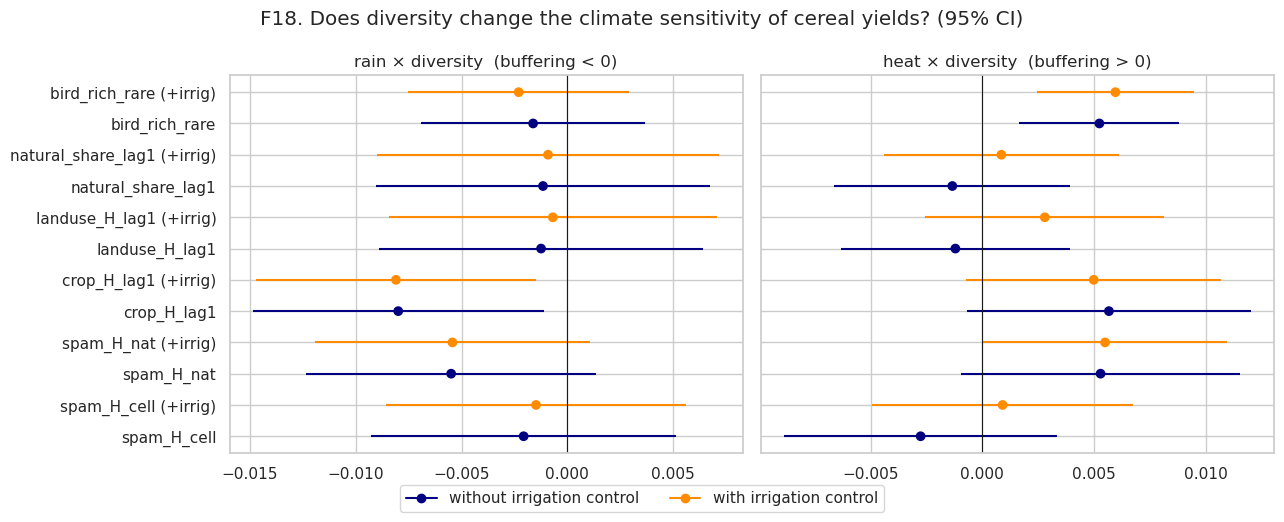

In [24]:
import statsmodels.formula.api as smf

def zc(s):
    return (s - s.mean()) / s.std()

def buffer_model(df, D, rain='rain_z', heat='heat_z', control_irrig=False, time_varying=False):
    control_irrig = control_irrig and bool(have(df, ['irrig_share']))
    cols = ['anom_w', rain, heat, D, 'iso3', 'year'] + (['irrig_share'] if control_irrig else [])
    d = df.dropna(subset=cols).copy()
    d['Dz'] = zc(d[D])
    d['R'], d['H'] = d[rain], d[heat]
    f = 'anom_w ~ R + H + R:Dz + H:Dz + C(iso3) + C(year)'
    if time_varying:
        f += ' + Dz'
    if control_irrig:
        d['Iz'] = zc(d['irrig_share'])
        f += ' + R:Iz + H:Iz'
    r = smf.ols(f, data=d).fit(cov_type='cluster', cov_kwds={'groups': pd.factorize(d['iso3'])[0]})
    return r, d

DIVS = {'spam_H_cell': False, 'spam_H_nat': False, 'crop_H_lag1': True, 'landuse_H_lag1': True,
        'natural_share_lag1': True, 'bird_rich_rare': False}
cer = pan[pan['crop'] == 'cereals']
cer_b = cer.dropna(subset=['anom_w', 'rain_z', 'heat_z'])
b0 = smf.ols('anom_w ~ rain_z + heat_z + C(iso3) + C(year)', data=cer_b).fit(
    cov_type='cluster', cov_kwds={'groups': pd.factorize(cer_b['iso3'])[0]})
print('Baseline (climate only):', b0.params[['rain_z', 'heat_z']].round(4).to_dict(),
      '| p =', b0.pvalues[['rain_z', 'heat_z']].round(3).to_dict(), '| R2 =', round(b0.rsquared, 3))

res = []
for D, tv in DIVS.items():
    if D not in cer.columns or cer[D].notna().sum() < 100:
        continue
    for ctrl in [False, True]:
        r, d = buffer_model(cer, D, control_irrig=ctrl, time_varying=tv)
        for term in ['R:Dz', 'H:Dz']:
            ci = r.conf_int().loc[term]
            res.append({'diversity': D, 'irrig_control': ctrl, 'term': term, 'coef': r.params[term],
                        'lo': ci[0], 'hi': ci[1], 'p': r.pvalues[term], 'n': int(r.nobs),
                        'countries': d['iso3'].nunique(), 'R2': r.rsquared})
res = pd.DataFrame(res)
res.to_csv(f'{OUT}/results_buffering_fe.csv', index=False)
print(res.round(4).to_string(index=False))

# F18. Forest plot of interaction terms
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, term, ttl in zip(axes, ['R:Dz', 'H:Dz'], ['rain × diversity  (buffering < 0)', 'heat × diversity  (buffering > 0)']):
    d = res[res['term'] == term].reset_index(drop=True)
    ypos = np.arange(len(d))
    col = np.where(d['irrig_control'], 'darkorange', 'navy')
    ax.errorbar(d['coef'], ypos, xerr=[d['coef'] - d['lo'], d['hi'] - d['coef']], fmt='none', ecolor=col)
    ax.scatter(d['coef'], ypos, c=col, zorder=3)
    ax.axvline(0, color='k', lw=0.8)
    ax.set_yticks(ypos); ax.set_yticklabels([f"{a}{' (+irrig)' if b else ''}" for a, b in zip(d['diversity'], d['irrig_control'])])
    ax.set_title(ttl)
from matplotlib.lines import Line2D
fig.legend(handles=[Line2D([], [], color='navy', marker='o', label='without irrigation control'),
                    Line2D([], [], color='darkorange', marker='o', label='with irrigation control')],
           loc='lower center', ncol=2, bbox_to_anchor=(0.5, -0.04))
fig.suptitle('F18. Does diversity change the climate sensitivity of cereal yields? (95% CI)')
savefig('F18_forest_buffering')

In [25]:
# Per-crop models and scale-sensitivity of the main result
rows = []
for crop in ['cereals', 'wheat', 'rice', 'maize']:
    r, d = buffer_model(pan[pan['crop'] == crop], 'spam_H_cell', control_irrig=True)
    rows.append({'test': f'crop = {crop}', 'coef_R:Dz': r.params['R:Dz'], 'p_R:Dz': r.pvalues['R:Dz'],
                 'coef_H:Dz': r.params['H:Dz'], 'p_H:Dz': r.pvalues['H:Dz'], 'n': int(r.nobs)})
for k, lab in [('u', 'climate: whole-country mean'), ('m', 'climate: cropland mask'), ('', 'climate: cropland-weighted')]:
    rz, hz = (f'rain_z_{k}', f'heat_z_{k}') if k else ('rain_z', 'heat_z')
    r, d = buffer_model(cer, 'spam_H_cell', rain=rz, heat=hz, control_irrig=True)
    rows.append({'test': lab, 'coef_R:Dz': r.params['R:Dz'], 'p_R:Dz': r.pvalues['R:Dz'],
                 'coef_H:Dz': r.params['H:Dz'], 'p_H:Dz': r.pvalues['H:Dz'], 'n': int(r.nobs)})
for D in have(cer, SPAM_SCALES + ['landuse_H_lag1', 'natural_share_lag1']):
    r, d = buffer_model(cer, D, control_irrig=True)
    rows.append({'test': f'diversity = {D}', 'coef_R:Dz': r.params['R:Dz'], 'p_R:Dz': r.pvalues['R:Dz'],
                 'coef_H:Dz': r.params['H:Dz'], 'p_H:Dz': r.pvalues['H:Dz'], 'n': int(r.nobs)})
r, d = buffer_model(cer.assign(anom_w=cer['anom_q']), 'spam_H_cell', control_irrig=True)
rows.append({'test': 'quadratic detrending', 'coef_R:Dz': r.params['R:Dz'], 'p_R:Dz': r.pvalues['R:Dz'],
             'coef_H:Dz': r.params['H:Dz'], 'p_H:Dz': r.pvalues['H:Dz'], 'n': int(r.nobs)})
sens = pd.DataFrame(rows)
sens.to_csv(f'{OUT}/results_sensitivity.csv', index=False)
print(sens.round(4).to_string(index=False))

                          test  coef_R:Dz  p_R:Dz  coef_H:Dz  p_H:Dz    n
                crop = cereals    -0.0015  0.6818     0.0009  0.7609 2961
                  crop = wheat    -0.0130  0.0179     0.0001  0.9891 1764
                   crop = rice    -0.0001  0.9729    -0.0006  0.8672 1680
                  crop = maize     0.0018  0.6589    -0.0038  0.1688 2268
   climate: whole-country mean    -0.0008  0.7938     0.0013  0.6108 2961
        climate: cropland mask    -0.0010  0.7748     0.0001  0.9763 2961
    climate: cropland-weighted    -0.0015  0.6818     0.0009  0.7609 2961
       diversity = spam_H_cell    -0.0015  0.6818     0.0009  0.7609 2961
    diversity = spam_H_0.25deg    -0.0027  0.4610     0.0022  0.4487 2961
     diversity = spam_H_0.5deg    -0.0030  0.4129     0.0029  0.3220 2961
       diversity = spam_H_1deg    -0.0033  0.3738     0.0035  0.2258 2961
       diversity = spam_H_2deg    -0.0037  0.3069     0.0040  0.1693 2961
        diversity = spam_H_nat    -0.0

## Step 15 — Machine learning: predicting yield anomalies (Ridge, Random Forest, XGBoost, LightGBM)

              cv                      features        model      R2   RMSE    MAE
unseen countries                  climate only        Ridge  0.0413 0.1223 0.0861
unseen countries                  climate only RandomForest  0.0161 0.1239 0.0881
unseen countries                  climate only      XGBoost -0.0244 0.1264 0.0903
unseen countries                  climate only     LightGBM -0.0507 0.1280 0.0922
unseen countries             climate + context        Ridge  0.0414 0.1223 0.0859
unseen countries             climate + context RandomForest  0.0417 0.1223 0.0858
unseen countries             climate + context      XGBoost -0.0106 0.1256 0.0889
unseen countries             climate + context     LightGBM -0.0174 0.1260 0.0891
unseen countries climate + context + diversity        Ridge  0.0412 0.1223 0.0859
unseen countries climate + context + diversity RandomForest  0.0531 0.1216 0.0854
unseen countries climate + context + diversity      XGBoost  0.0012 0.1248 0.0885
unseen countries

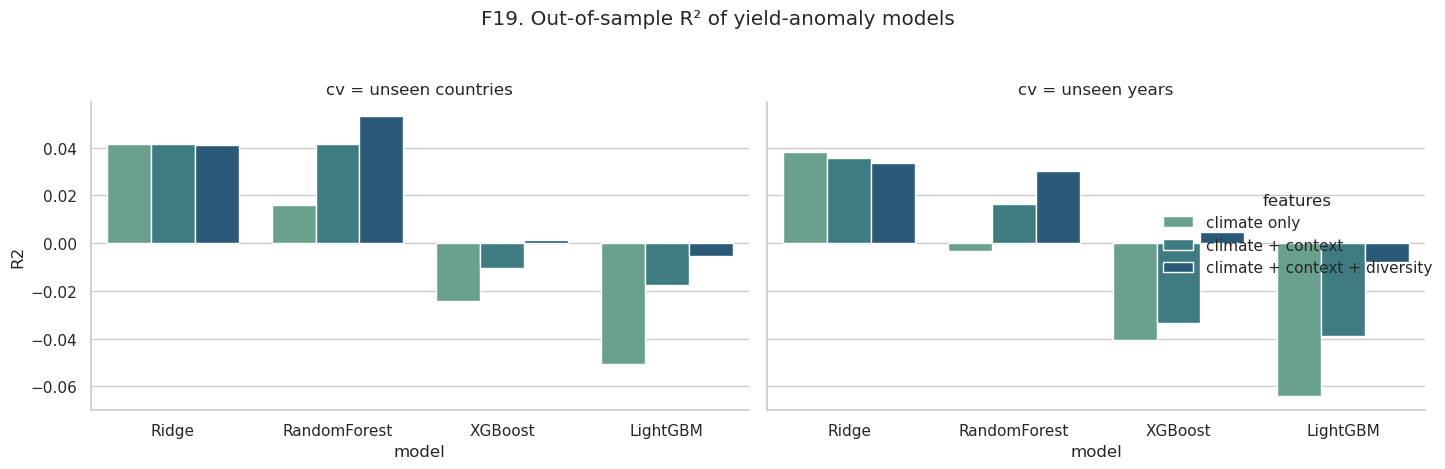

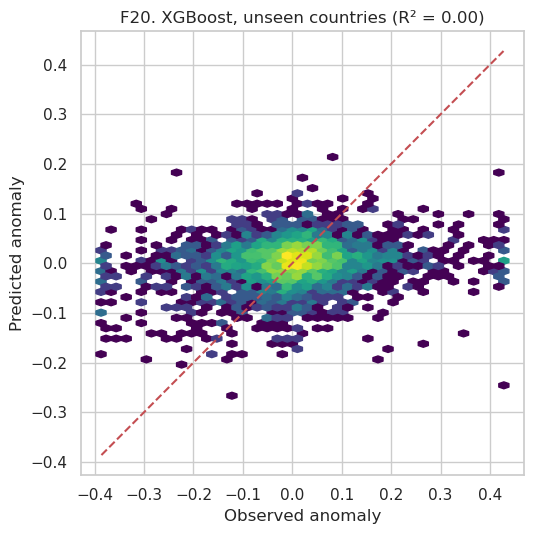

In [26]:
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, QuantileTransformer
from sklearn.linear_model import RidgeCV, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, roc_auc_score, average_precision_score, RocCurveDisplay
from xgboost import XGBRegressor, XGBClassifier
from lightgbm import LGBMRegressor, LGBMClassifier

F_CLIM = [c for c in ['rain_z', 'heat_z', 'tmax_z', 'dry_months', 'hot_months', 'rain_ann_z', 'heat_ann_z'] if c in pan]
F_DIV = [c for c in ['crop_H_lag1', 'spam_H_cell', 'spam_H_nat', 'landuse_H_lag1', 'natural_share_lag1',
                     'forest_share_lag1', 'bird_rich_rare'] if c in have(pan, [c])]
F_CTX = [c for c in ['irrig_share', 'cereal_share', 'log_mean_yield'] if c in pan]
FEATURE_SETS = {'climate only': F_CLIM, 'climate + context': F_CLIM + F_CTX,
                'climate + context + diversity': F_CLIM + F_CTX + F_DIV}

ml = pan[(pan['crop'] == 'cereals')].dropna(subset=['anom_w', 'rain_z', 'heat_z']).reset_index(drop=True)
y = ml['anom_w'].values

def reg_models():
    return {
        'Ridge': make_pipeline(SimpleImputer(strategy='median'), QuantileTransformer(n_quantiles=200, output_distribution='normal'),
                               StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 20))),   # robust to extreme countries
        'RandomForest': make_pipeline(SimpleImputer(strategy='median'),
                                      RandomForestRegressor(n_estimators=500, min_samples_leaf=5, n_jobs=-1, random_state=0)),
        'XGBoost': XGBRegressor(n_estimators=600, max_depth=4, learning_rate=0.03, subsample=0.8, colsample_bytree=0.8,
                                min_child_weight=5, reg_lambda=1.0, random_state=0, n_jobs=-1),
        'LightGBM': LGBMRegressor(n_estimators=600, learning_rate=0.03, num_leaves=15, min_child_samples=20,
                                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=0, verbose=-1)}

metrics, preds = [], {}
for cv_name, groups in [('unseen countries', ml['iso3']), ('unseen years', ml['year'])]:
    for fs_name, cols in FEATURE_SETS.items():
        X = ml[cols]
        for mname, model in reg_models().items():
            p = cross_val_predict(model, X, y, groups=groups, cv=GroupKFold(n_splits=5))
            preds[(cv_name, fs_name, mname)] = p
            metrics.append({'cv': cv_name, 'features': fs_name, 'model': mname, 'R2': r2_score(y, p),
                            'RMSE': mean_squared_error(y, p) ** 0.5, 'MAE': mean_absolute_error(y, p)})
metrics = pd.DataFrame(metrics)
metrics.to_csv(f'{OUT}/results_ml_regression.csv', index=False)
print(metrics.round(4).to_string(index=False))

# F19. Model comparison
g = sns.catplot(data=metrics, x='model', y='R2', hue='features', col='cv', kind='bar', height=4.5, aspect=1.3, palette='crest')
g.fig.suptitle('F19. Out-of-sample R² of yield-anomaly models', y=1.04)
savefig('F19_ml_comparison')

# F20. Predicted vs observed (best full model, unseen countries)
p = preds[('unseen countries', 'climate + context + diversity', 'XGBoost')]
plt.figure(figsize=(5.5, 5.5))
plt.hexbin(y, p, gridsize=40, cmap='viridis', bins='log')
lim = [np.percentile(y, 1), np.percentile(y, 99)]
plt.plot(lim, lim, 'r--'); plt.xlabel('Observed anomaly'); plt.ylabel('Predicted anomaly')
plt.title(f'F20. XGBoost, unseen countries (R² = {r2_score(y, p):.2f})')
savefig('F20_pred_vs_obs')

## Step 16 — Machine learning: classifying yield-shock years

Shock years: 474 of 2982 (15.9%)


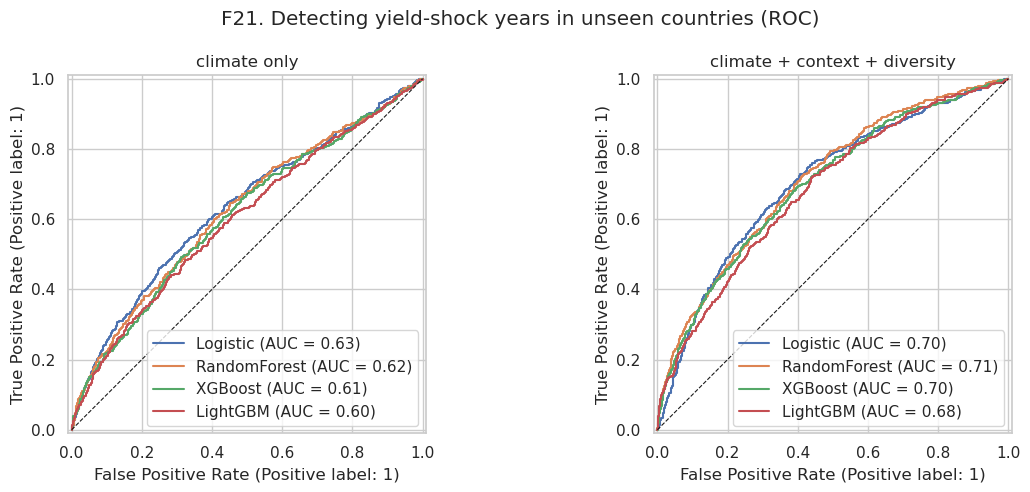

                     features        model  ROC_AUC  PR_AUC
                 climate only     Logistic    0.631   0.259
                 climate only RandomForest    0.623   0.257
                 climate only      XGBoost    0.610   0.245
                 climate only     LightGBM    0.600   0.240
climate + context + diversity     Logistic    0.704   0.297
climate + context + diversity RandomForest    0.711   0.344
climate + context + diversity      XGBoost    0.698   0.322
climate + context + diversity     LightGBM    0.683   0.320 
No-skill PR-AUC = 0.159


In [27]:
ml['shock'] = (ml['anom'] < -0.10).astype(int)
ys = ml['shock'].values
print('Shock years:', ys.sum(), 'of', len(ys), f'({ys.mean():.1%})')
spw = (1 - ys.mean()) / ys.mean()

def clf_models():
    return {
        'Logistic': make_pipeline(SimpleImputer(strategy='median'), QuantileTransformer(n_quantiles=200, output_distribution='normal'), StandardScaler(),
                                  LogisticRegression(max_iter=2000, class_weight='balanced')),
        'RandomForest': make_pipeline(SimpleImputer(strategy='median'),
                                      RandomForestClassifier(n_estimators=500, min_samples_leaf=5, class_weight='balanced',
                                                             n_jobs=-1, random_state=0)),
        'XGBoost': XGBClassifier(n_estimators=500, max_depth=3, learning_rate=0.03, subsample=0.8, colsample_bytree=0.8,
                                 min_child_weight=5, scale_pos_weight=spw, eval_metric='logloss', random_state=0, n_jobs=-1),
        'LightGBM': LGBMClassifier(n_estimators=500, learning_rate=0.03, num_leaves=15, min_child_samples=20,
                                   class_weight='balanced', random_state=0, verbose=-1)}

cmet = []
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, fs_name in zip(axes, ['climate only', 'climate + context + diversity']):
    X = ml[FEATURE_SETS[fs_name]]
    for mname, model in clf_models().items():
        pp = cross_val_predict(model, X, ys, groups=ml['iso3'], cv=GroupKFold(n_splits=5), method='predict_proba')[:, 1]
        cmet.append({'features': fs_name, 'model': mname, 'ROC_AUC': roc_auc_score(ys, pp),
                     'PR_AUC': average_precision_score(ys, pp)})
        RocCurveDisplay.from_predictions(ys, pp, name=mname, ax=ax)
    ax.plot([0, 1], [0, 1], 'k--', lw=0.8); ax.set_title(fs_name)
fig.suptitle('F21. Detecting yield-shock years in unseen countries (ROC)')
savefig('F21_roc_shock')
cmet = pd.DataFrame(cmet)
cmet.to_csv(f'{OUT}/results_ml_classification.csv', index=False)
print(cmet.round(3).to_string(index=False), '\nNo-skill PR-AUC =', round(ys.mean(), 3))

## Step 17 — Explaining the models (SHAP and buffering curves)

/home/pranathi-sindhu/miniconda3/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


shap.TreeExplainer failed, using XGBoost built-in SHAP values: could not convert string to float: '[-1.4751138E-4]'


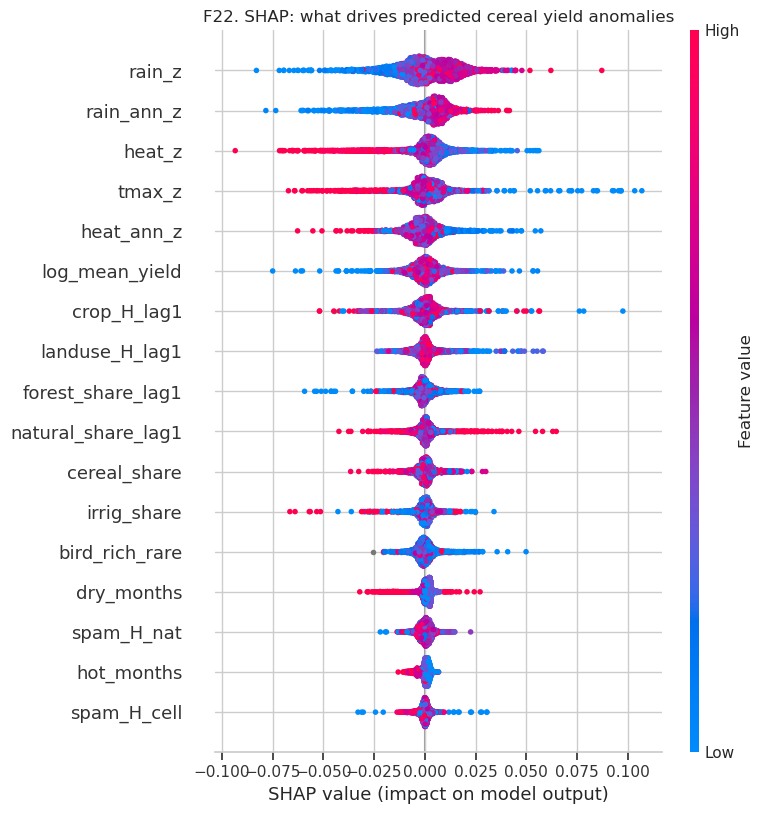

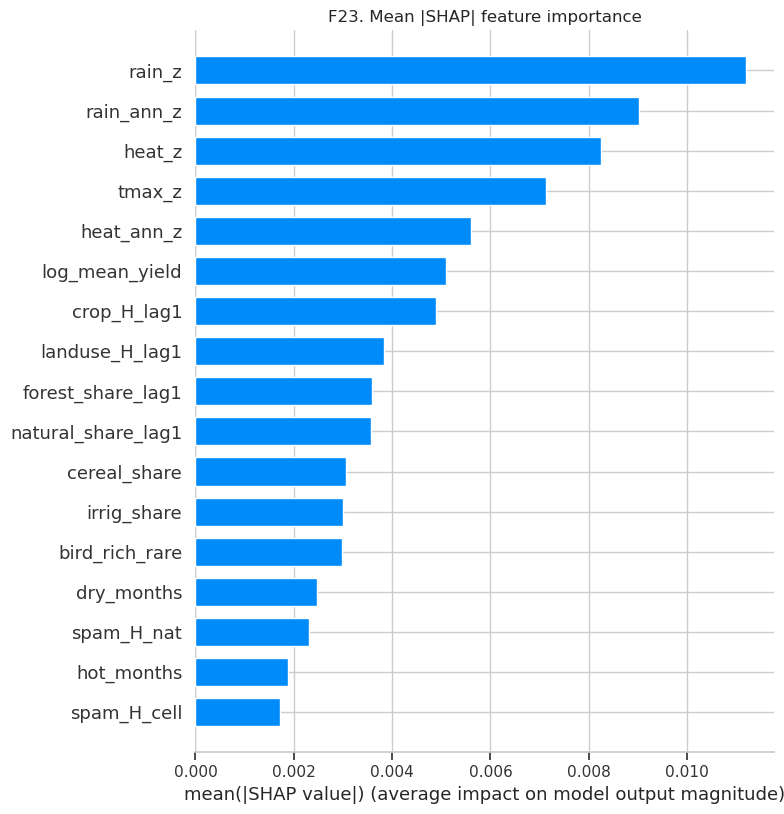

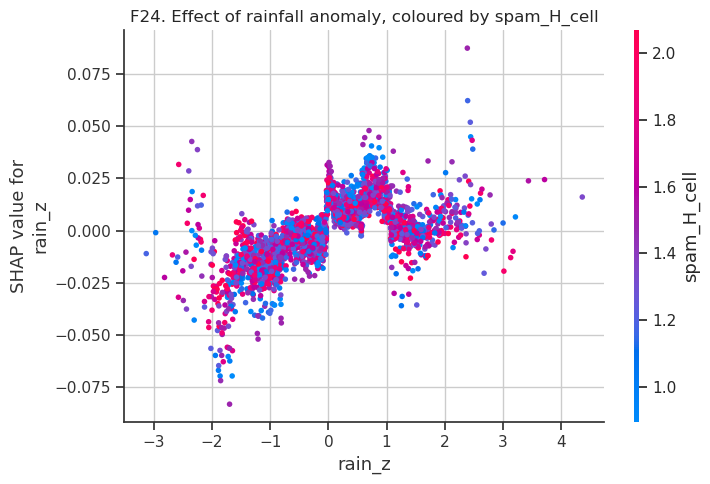

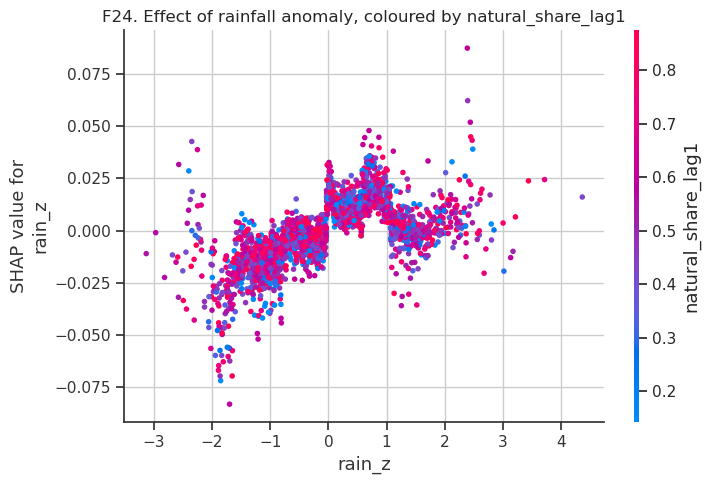

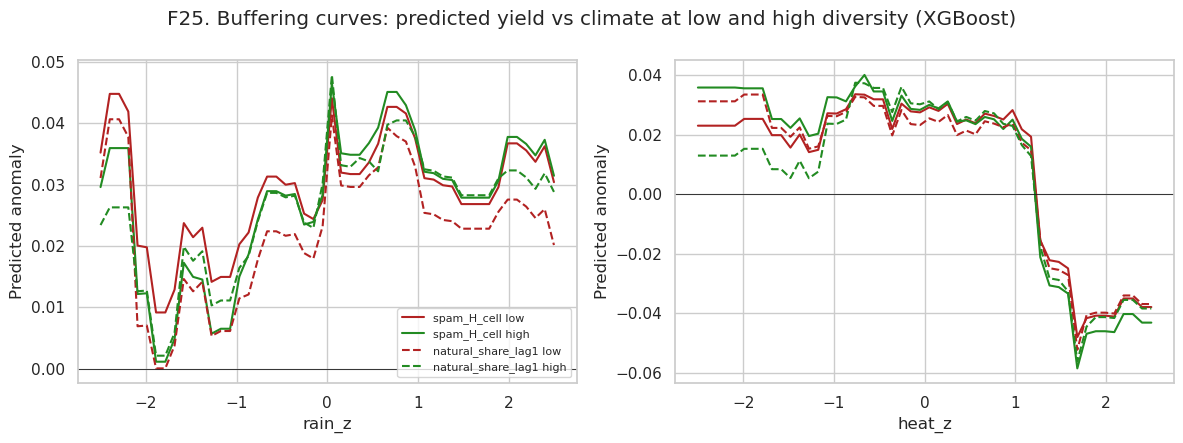

In [28]:
import shap

FULL = FEATURE_SETS['climate + context + diversity']
Xf = ml[FULL]
xgb = reg_models()['XGBoost'].fit(Xf, y)
try:
    sv = shap.TreeExplainer(xgb).shap_values(Xf)
except Exception as e:                       # some shap/xgboost version pairs disagree; XGBoost can compute SHAP itself
    print('shap.TreeExplainer failed, using XGBoost built-in SHAP values:', str(e)[:80])
    import xgboost
    sv = xgb.get_booster().predict(xgboost.DMatrix(Xf), pred_contribs=True)[:, :-1]

shap.summary_plot(sv, Xf, show=False)
plt.title('F22. SHAP: what drives predicted cereal yield anomalies')
savefig('F22_shap_summary')

shap.summary_plot(sv, Xf, plot_type='bar', show=False)
plt.title('F23. Mean |SHAP| feature importance')
savefig('F23_shap_bar')

for div_col in ['spam_H_cell', 'natural_share_lag1', 'spam_H_nat'][:2 if 'natural_share_lag1' in FULL else 3]:
    if div_col in FULL:
        shap.dependence_plot('rain_z', sv, Xf, interaction_index=div_col, show=False)
        plt.title(f'F24. Effect of rainfall anomaly, coloured by {div_col}')
        savefig(f'F24_shap_dep_rain_{div_col}')

# Buffering curves (manual partial dependence)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
med = Xf.median()
for ax, (clim_var, rng) in zip(axes, [('rain_z', (-2.5, 2.5)), ('heat_z', (-2.5, 2.5))]):
    grid = np.linspace(*rng, 50)
    for div_col, ls in [('spam_H_cell', '-'), ('natural_share_lag1' if 'natural_share_lag1' in FULL else 'bird_rich_rare', '--')]:
        if div_col not in FULL:
            continue
        for q, col in [(0.1, 'firebrick'), (0.9, 'forestgreen')]:
            Xg = pd.DataFrame([med] * len(grid))
            Xg[clim_var] = grid
            Xg[div_col] = Xf[div_col].quantile(q)
            ax.plot(grid, xgb.predict(Xg[FULL]), ls=ls, color=col,
                    label=f'{div_col} {"low" if q < .5 else "high"}')
    ax.axhline(0, color='k', lw=0.6); ax.set_xlabel(clim_var); ax.set_ylabel('Predicted anomaly')
axes[0].legend(fontsize=8)
fig.suptitle('F25. Buffering curves: predicted yield vs climate at low and high diversity (XGBoost)')
savefig('F25_buffering_curves')

## Step 18 — Country-level view: drought sensitivity vs diversity

spam_H_cell          coef = -0.0031  p = 0.744  n = 141
crop_H_base          coef = -0.0164  p = 0.019  n = 141
landuse_H_base       coef = -0.0017  p = 0.905  n = 141
natural_share_base   coef = -0.0042  p = 0.822  n = 141
bird_rich_rare       coef = -0.0000  p = 0.619  n = 136


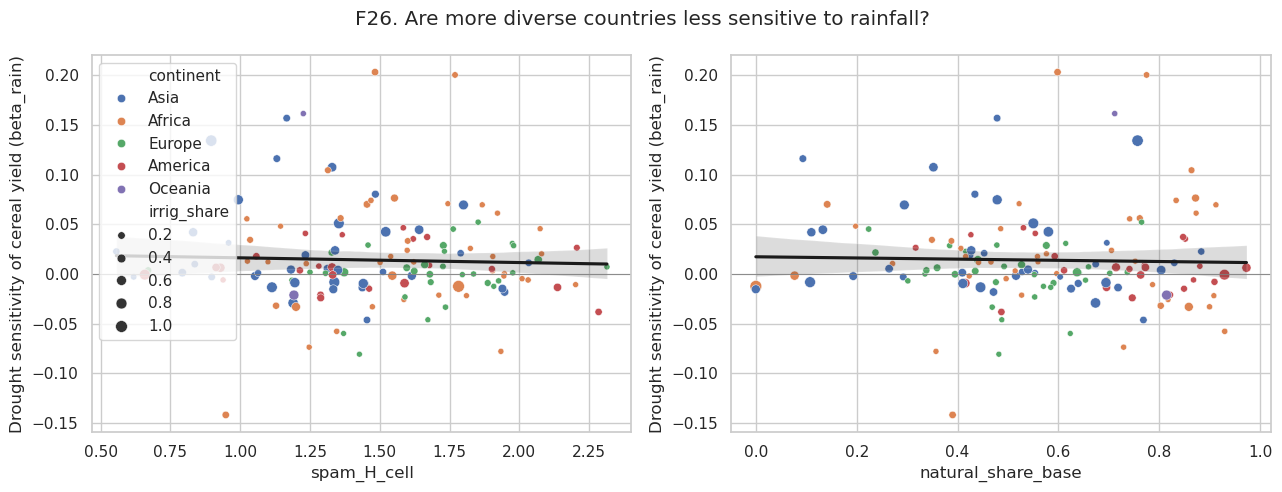

In [29]:
beta = []
for iso, d in cer.dropna(subset=['rain_z', 'heat_z']).groupby('iso3'):
    if len(d) >= 15:
        r = smf.ols('anom_w ~ rain_z + heat_z', data=d).fit()
        beta.append({'iso3': iso, 'beta_rain': r.params['rain_z'], 'beta_heat': r.params['heat_z']})
beta = pd.DataFrame(beta).merge(cs, on='iso3', how='left')
beta.to_csv(f'{OUT}/country_sensitivity.csv', index=False)

for D in have(beta, ['spam_H_cell', 'crop_H_base', 'landuse_H_base', 'natural_share_base', 'bird_rich_rare']):
    ctrl = have(beta, ['irrig_share'])
    d = beta.dropna(subset=[D] + ctrl)
    r = smf.ols(f'beta_rain ~ {D}' + ''.join(f' + {c}' for c in ctrl), data=d).fit(cov_type='HC3')
    print(f'{D:20s} coef = {r.params[D]: .4f}  p = {r.pvalues[D]:.3f}  n = {int(r.nobs)}')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, D in zip(axes, have(beta, ['spam_H_cell', 'natural_share_base', 'crop_H_base'])[:2]):
    sns.scatterplot(data=beta, x=D, y='beta_rain', hue='continent', size='irrig_share' if have(beta, ['irrig_share']) else None, ax=ax)
    sns.regplot(data=beta, x=D, y='beta_rain', scatter=False, ax=ax, color='k')
    ax.axhline(0, color='grey', lw=0.6)
    ax.set_ylabel('Drought sensitivity of cereal yield (beta_rain)')
axes[1].legend().set_visible(False)
fig.suptitle('F26. Are more diverse countries less sensitive to rainfall?')
savefig('F26_sensitivity_vs_diversity')

## Step 19 — Save everything for the slides

In [30]:
summary = {
    'study countries': len(STUDY),
    'country-years (cereals)': int((pan['crop'] == 'cereals').sum()),
    'baseline rain_z coef': round(b0.params['rain_z'], 4), 'baseline rain_z p': round(b0.pvalues['rain_z'], 4),
    'baseline heat_z coef': round(b0.params['heat_z'], 4), 'baseline heat_z p': round(b0.pvalues['heat_z'], 4),
    'best ML R2 (unseen countries)': round(metrics[metrics['cv'] == 'unseen countries']['R2'].max(), 3),
    'best shock ROC-AUC': round(cmet['ROC_AUC'].max(), 3),
}
print(pd.Series(summary).to_string())
pd.Series(summary).to_csv(f'{OUT}/summary_numbers.csv')
print('\nFigures saved in', FIG)
print(sorted(os.listdir(FIG)))

study countries                   142.0000
country-years (cereals)          2982.0000
baseline rain_z coef                0.0160
baseline rain_z p                   0.0001
baseline heat_z coef               -0.0182
baseline heat_z p                   0.0000
best ML R2 (unseen countries)       0.0530
best shock ROC-AUC                  0.7110

Figures saved in /home/pranathi-sindhu/EST_final/outputs/figs
['F01_cereal_composition.png', 'F02_map_instability.png', 'F03_map_crop_div.png', 'F04_map_land_div.png', 'F05_map_birds.png', 'F06_yield_series.png', 'F07_mapspam_cell_diversity.png', 'F07b_spam_scale_effect.png', 'F08_anomaly_distribution.png', 'F09_rain_heatmap.png', 'F10_climate_trends.png', 'F11_weighting_effect.png', 'F12_crop_div_trends.png', 'F13_correlation_heatmap.png', 'F14_diversity_vs_instability.png', 'F15_stress_by_diversity.png', 'F16_missing_data.png', 'F17_scale_sensitivity_inputs.png', 'F17b_worldcover_scales.png', 'F17c_worldcover_scale_curve.png', 'F18_forest_buffer